# DSA5205 Project 2 — Ridge-Based Cross-Sectional Equity Strategy

**Validation, out-of-sample evaluation, and exploratory extensions**

This notebook studies one primary strategy:

> Eligible stock universe → 3×3 momentum–volatility double sorting → Ridge return prediction → Top-10 selection → equal-weight allocation → monthly rebalancing → out-of-sample evaluation net of transaction costs.

Ridge is the **primary research model**, designated on economic and diagnostic grounds rather than by an automatic minimum-MSE rule. LASSO, Random Forest and XGBoost are alternative forecasting models on the same prediction task. B1, B3, SPY and QQQ provide trading baselines and investable benchmarks. The original exploratory Ridge extension is retained as an explicitly exploratory analysis.

The notebook is organised in fourteen sections that follow the research argument from hypothesis to final evaluation and reproducibility.

## 1. Research Question and Economic Motivation

The research question is whether Ridge Regression, trained on economically motivated financial predictors, can generate useful cross-sectional stock rankings and improve a systematic equity portfolio relative to simpler investment alternatives.

Cross-sectional momentum assumes that recent relative performance carries information about near-future relative performance. A single momentum rank uses one signal. A regression model can combine several weak, correlated characteristics — momentum at several horizons, volatility, market beta, trend, drawdown, liquidity and trading activity — into one expected-return score. The economic question is whether that combination is genuine or mostly fitted noise.

The strategy is deliberately simple in its portfolio layer. At each month-end it screens a liquid universe with a momentum × volatility double sort, ranks the resulting thirty candidates with Ridge, buys the ten highest predicted returns at equal weights, and executes at the next open. This keeps the forecasting question separate from portfolio engineering.

Three contributions follow. First, the project evaluates Ridge against three materially different forecasting algorithms on an identical prediction problem. Second, it grounds the Ridge choice in the correlation structure of the predictors and in rolling coefficient-stability diagnostics rather than in a single validation metric. Third, it reports the primary strategy against momentum baselines and investable ETFs on a common out-of-sample window, and it discloses where the machine-learning ranking fails to improve on simpler rules.

**A note on chronology.** The original project pre-specified Ridge. A later engineering revision added an automatic lowest-validation-MSE rule, which selected LASSO. This notebook restores the original Ridge designation on economic and diagnostic grounds, archives the LASSO audit, and reports both. The project history includes prior out-of-sample review, so the designation is not a clean pre-registration; Section 7 states this explicitly.

## 2. Markets, Assets, Trading Calendar and Benchmarks

The traded assets are US large-capitalisation equities drawn from the S&P 500 constituent list, plus the SPY and QQQ ETFs as benchmarks. The base currency is the US dollar and the trading calendar is the NYSE session calendar.

Decisions are made after the close of the last trading session of each calendar month. Execution occurs at the open of the next observed session. The holding period therefore runs from one monthly execution open to the next monthly execution open. No intraday information is used.

| Strategy | Role | Selection | Weighting |
|---|---|---|---|
| Ridge | Primary research strategy | 3×3 screened 30 candidates, Ridge Top 10 | Equal 10% |
| LASSO | Alternative ML model | Same candidates, LASSO Top 10 | Equal 10% |
| Random Forest | Alternative ML model | Same candidates, RF Top 10 | Equal 10% |
| XGBoost | Alternative ML model | Same candidates, XGB Top 10 | Equal 10% |
| B1 Momentum10 | Momentum baseline | Momentum Top 10 from the liquid universe | Equal 10% |
| B3 MomentumDoubleSort10 | Momentum baseline | Momentum Top 10 within the same 3×3 pool | Equal 10% |
| SPY | Investable benchmark | Buy-and-hold S&P 500 ETF | Fully invested |
| QQQ | Investable benchmark | Buy-and-hold Nasdaq-100 ETF | Fully invested |

B1 and B3 are trading baselines, not investable index products: they are systematic rules constructed from the same data. SPY and QQQ are investable buy-and-hold alternatives. The distinction matters when interpreting excess returns.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, warnings
warnings.filterwarnings('ignore', message='An input array is constant')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

def find_project_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for candidate in [here, *here.parents]:
        if (candidate / 'src' / 'pipeline.py').exists() and (candidate / 'config' / 'experiment_config.yaml').exists():
            return candidate
    raise RuntimeError('Run this notebook from inside the integrated project folder')

PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_pipeline import (
    load_config, load_model_ready, chronological_splits, data_quality_report,
    resolve, ensure_output_dirs,
)
from src.pipeline import FEATURES
from src.features import describe_features
from src.models import MODEL_NAMES, MODEL_LABELS, parameter_grid, build_model
from src.metrics import metric_definitions, prediction_metrics, portfolio_metrics
from src.validation import run_validation
from src.research_policy import (
    designate_primary_model, require_primary_designation, designation_table,
    PRIMARY_MODEL, POLICY_NAME,
)
from src.final_refit import refit_models
from src.oos_evaluation import run_oos
from src.ridge_extension import run_ridge_extension, NINE_STRATEGIES
from src.oos_comparison import run_eight_strategy_comparison, DISPLAY as STRATEGY_DISPLAY
from src.score_position import run_score_position_example
from src.diagnostics import load_diagnostics, validate_diagnostics, strong_pairs_table, make_report_figures
from src.visualization import plot_validation_dashboard, plot_oos_dashboard
from src.utils import environment_info

pd.set_option('display.width', 230)
pd.set_option('display.max_columns', 90)
plt.rcParams['figure.dpi'] = 110

cfg = load_config()
ensure_output_dirs(cfg)
print('Project root :', PROJECT_ROOT.name)
print('Frequency    :', cfg['project']['frequency'])
print('Primary model:', PRIMARY_MODEL)
print('Policy       :', POLICY_NAME)
print('Target       :', cfg['target'])

Project root : DSA5205_Project2_Final
Frequency    : monthly
Primary model: ridge
Policy       : ridge_primary_economic_designation
Target       : target_forward_return


In [2]:
df = load_model_ready(cfg)
splits, split_summary, embargo_excluded = chronological_splits(df, cfg)
quality = data_quality_report(df, splits)

display(pd.DataFrame([{
    'rows': quality['n_rows'],
    'decision_dates': quality['n_decision_dates'],
    'first_decision': quality['decision_start'],
    'last_decision': quality['decision_end'],
    'features': quality['n_features'],
    'candidates_per_date': quality['rows_per_date_min'],
    'quality_pass': quality['pass'],
}]))
display(split_summary)

,rows,decision_dates,first_decision,last_decision,features,candidates_per_date,quality_pass
0,5760,192,2010-01-29,2025-12-31,15,30,True


,split,decision_start,decision_end,label_end_max,n_decision_dates,n_rows,n_tickers,label_embargo
0,train,2010-01-29,2019-10-31,2019-12-02,118,3540,396,strict_cutoff
1,validation,2020-01-31,2021-10-29,2021-12-01,22,660,256,strict_cutoff
2,refit,2010-01-29,2021-10-29,2021-12-01,142,4260,417,strict_cutoff
3,test,2022-01-31,2025-12-31,2026-02-02,48,1440,335,strict_cutoff


### 2.5 The Top-300 liquidity universe

The candidate universe is built from three filters applied at the decision close. A stock must have a close of at least \$5, a twenty-day average daily dollar volume (`ADV20`, the mean of close × volume over the last 20 sessions) of at least \$10 million, and raw price coverage of at least 95% over the 21-, 63- and 252-session windows. It must also have finite values for all fifteen features. The 300 most liquid eligible names by ADV20 are retained.

The 300-name cap is a fixed design choice, not a parameter chosen on the test period. It serves four purposes: it keeps the universe tradable; it reduces exposure to illiquid names; it provides enough cross-sectional breadth for a 3×3 sort; and it makes candidate construction consistent across months. In this data snapshot every month reached the 300-name cap, but the rule does not guarantee that: a month with fewer than 90 eligible names is skipped rather than padded with ineligible stocks.

### 2.6 The 3×3 double sort and the 3–4–3 allocation

The screen is a dependent double sort, implemented in the preserved pipeline. First, eligible stocks are ranked by `mom_2_12` in descending order and split into three approximately equal momentum groups: high, medium and low. Second, within each momentum group, stocks are sorted by `vol_63` in ascending order and split into three approximately equal volatility cells: low, medium and high. Third, each cell contributes a fixed number of candidates: 3 from the low-volatility cell, 4 from the medium-volatility cell and 3 from the high-volatility cell. Each momentum group therefore contributes ten names and the screen produces thirty candidates.

The within-cell ranking depends on the momentum group. The high-momentum group takes the highest `mom_2_12` names in the cell, the low-momentum group takes the lowest, and the medium-momentum group takes the names closest to the cell median. Ties are broken by ticker in ascending order. If a cell contains fewer names than required, the decision date is skipped rather than filled with names outside the cell.

The 3–4–3 allocation is symmetric because ten candidates cannot be divided evenly into three volatility cells. Assigning the additional candidate to the middle cell avoids favouring either volatility extreme. It is a fixed, interpretable design choice; the project does not claim that 3–4–3 is empirically optimal or that medium-volatility stocks are superior. The screen is risk-characteristic-aware, but it does not minimise portfolio variance and it does not guarantee that the final ten holdings are diversified across volatility groups.

## 3. Data Sources, Cleaning and Universe Construction

Prices, volumes, dividends and splits come from Yahoo Finance through the original `yfinance` download pipeline. The constituent list is the current S&P 500 membership published on Wikipedia, backfilled through history. The pipeline computes features only from genuinely observed prices: missing sessions are not fabricated, and only auxiliary machine-learning features are forward-filled, with a two-session limit.

Eligibility at each decision date requires a price of at least $5, twenty-day average dollar volume of at least $10 million, at least 95% price coverage over the 21-, 63- and 252-session windows, and finite values for all fifteen features. The 300 most liquid eligible names form the liquid universe. A 3×3 momentum × volatility double sort then selects thirty candidates: three approximately equal momentum buckets, each split into three volatility buckets, with 3, 4 and 3 names taken from the low, medium and high volatility cells.

**Survivorship and constituent-selection bias.** The active stock universe is built from today's S&P 500 constituent list rather than point-in-time membership. Firms removed from the index are absent and current survivors are over-represented. This may overstate the active strategies' historical performance relative to SPY and QQQ, whose buy-and-hold returns are calculated directly from historical ETF prices and are not affected by the same constituent-selection mechanism. Data-vendor price adjustments and corporate-action treatment can affect both individual-stock histories and ETF return calculations. The direction or magnitude of the survivorship effect is not precisely measured here, and the limitation is not corrected.

The model-ready panel contains 5,760 candidate rows over 192 monthly decision dates, with exactly thirty names per date.

In [3]:
display(df.groupby('split').agg(
    rows=('ticker', 'size'),
    decision_dates=('decision_date', 'nunique'),
    first_decision=('decision_date', 'min'),
    last_decision=('decision_date', 'max'),
    tickers=('ticker', 'nunique'),
))
print('Quality issues:', quality['issues'])

,rows,decision_dates,first_decision,last_decision,tickers
split,,,,,
test,1440,48,2022-01-31,2025-12-31,335
train,3600,120,2010-01-29,2019-12-31,400
validation,720,24,2020-01-31,2021-12-31,262


Quality issues: []


## 4. Labels, Features and Timing Alignment

The prediction target is the next holding-period simple return computed from adjusted opens:

\[
y_t=\frac{\text{adjusted open at the next rebalance execution}}{\text{adjusted open at this rebalance execution}}-1 .
\]

Adjusted opens reflect dividends and splits. The decision date, execution date and label end date satisfy `decision_date < execution_date < label_end_date`, so the model never trades on information that is unavailable when the position is formed.

The fifteen features are organised into five economic groups. All are computed from data available at the decision close.

| Group | Feature | Definition and lookback | Economic interpretation |
|---|---|---|---|
| Momentum | `mom_21` | 21-session total return | Short-term continuation or reversal |
| Momentum | `mom_63` | 63-session total return | Quarterly momentum |
| Momentum | `mom_126` | 126-session total return | Semi-annual momentum |
| Momentum | `mom_2_12` | 12-month return skipping the most recent month | Classic 12-1 momentum, less short-term reversal |
| Momentum | `relative_mom_63` | 63-session stock return minus SPY return | Industry- and market-neutral relative strength |
| Volatility and risk | `vol_21` | Annualised 21-session realised volatility | Short-term risk |
| Volatility and risk | `vol_63` | Annualised 63-session realised volatility | Medium-term risk and the screening variable |
| Volatility and risk | `beta_252` | 252-session rolling beta to SPY | Systematic exposure |
| Volatility and risk | `drawdown_63` | Price relative to its 63-session high | Recent loss state |
| Technical trend | `ma_ratio_50` | Price relative to its 50-session moving average | Short-term trend |
| Technical trend | `ma_ratio_200` | Price relative to its 200-session moving average | Long-term trend |
| Technical trend | `rsi_14` | 14-session relative strength index | Overbought/oversold condition |
| Liquidity and activity | `ln_adv_20` | Log 20-session average dollar volume | Size and liquidity |
| Liquidity and activity | `volume_ratio_21` | Volume relative to its 21-session average | Abnormal trading activity |
| Price range | `range_hl` | High-low range scaled by close | Intraday price pressure |

Multiple lookback horizons are intentional. A one-month, one-quarter and two-quarter return need not carry the same information: short horizons are more sensitive to reversal and microstructure, while twelve-month momentum captures slower fundamental trends. The 12-1 construction deliberately skips the most recent month to reduce contamination from short-term reversal.

The feature set is compact and interpretable, not empirically optimal. Fifteen characteristics keep the parameter-to-observation ratio manageable and allow the coefficients to be read economically. No claim is made that fifteen is the best possible number.

**Cleaning and scaling.** Extreme values are not winsorised; the pipeline requires finite features and relies on the model's regularisation and on the screening filters. Ridge and LASSO standardise features inside a scikit-learn `Pipeline`, so scaling parameters are estimated only on the rows passed to `fit`. Tree models are scale-invariant. Missing values are not imputed inside the model: candidate rows must have finite values at the decision date.

**Leakage control.** A row enters training or tuning only if its label has settled by the split boundary. This removes the last two 2019 cohorts from training (their labels settle in January and February 2020) and the last two 2021 cohorts from validation (their labels settle in January and February 2022). The test slice is not loaded by the validation or designation stages.

In [4]:
features = describe_features()
display(features)

example_date = sorted(df.decision_date.unique())[24]
example = df.loc[df.decision_date == example_date].head(4)
display(example[[
    'decision_date', 'execution_date', 'label_end_date', 'ticker',
    'entry_adj_open', 'exit_adj_open', 'target_forward_return', 'spy_return', 'qqq_return',
]].round(6))
print('Ordering holds for every row:',
      bool(((df.decision_date < df.execution_date) & (df.execution_date < df.label_end_date)).all()))
display(embargo_excluded)

,feature,description,screening_feature,forward_filled_in_pipeline
0,mom_21,21-session total return,False,True
1,mom_63,63-session total return,False,True
2,mom_126,126-session total return,False,True
3,mom_2_12,12-month return skipping the most recent month...,True,False
4,relative_mom_63,63-session return minus SPY 63-session return,False,True
5,vol_21,annualised 21-session realised volatility,False,True
6,vol_63,annualised 63-session realised volatility,True,False
7,beta_252,252-session rolling beta to SPY,False,True
8,drawdown_63,current price relative to its 63-session high,False,True
9,ma_ratio_50,price relative to its 50-session moving average,False,True


,decision_date,execution_date,label_end_date,ticker,entry_adj_open,exit_adj_open,target_forward_return,spy_return,qqq_return
720,2012-01-31,2012-02-01,2012-03-01,BAC,5.577390,6.231272,0.117238,0.037947,0.061926
721,2012-01-31,2012-02-01,2012-03-01,BIIB,118.459999,116.010002,-0.020682,0.037947,0.061926
722,2012-01-31,2012-02-01,2012-03-01,BMY,20.024728,19.729249,-0.014756,0.037947,0.061926
723,2012-01-31,2012-02-01,2012-03-01,BNY,14.405164,15.721155,0.091356,0.037947,0.061926


Ordering holds for every row: True


,split,decision_date,label_end_date,cutoff,reason
0,train,2019-11-29,2020-01-02,2020-01-01,label settles after split boundary
1,train,2019-12-31,2020-02-03,2020-01-01,label settles after split boundary
2,validation,2021-11-30,2022-01-03,2022-01-01,label settles after split boundary
3,validation,2021-12-31,2022-02-01,2022-01-01,label settles after split boundary
4,refit,2021-11-30,2022-01-03,2022-01-01,label settles after split boundary
5,refit,2021-12-31,2022-02-01,2022-01-01,label settles after split boundary


## 5. Feature Correlation and Ridge Model Justification

The fifteen predictors are not orthogonal. Twelve of the 105 feature pairs have absolute training-period Pearson correlations of at least 0.70. The strongest pairs are momentum with moving-average ratios, long-horizon momentum with medium-horizon momentum, and short with medium realised volatility.

Correlation does not imply redundant economic information. A 63-day and a 126-day return measure different horizons even when they co-move; relative momentum and absolute momentum answer different questions; moving-average ratios and trailing returns are related but not identical transformations. Dropping every correlated feature would discard horizon-specific information and leave an arbitrary subset. Ridge instead keeps the full, economically motivated set and controls the variance of the combined coefficient vector with an L2 penalty.

The supplementary diagnostics in `results/diagnostics/` quantify the consequence. Across 59 rolling 60-month training windows estimated on the training period, the mean relative L2 change in standardised coefficients is **0.176 for Ridge** and **0.282 for LASSO**, so Ridge's coefficients change about **37.4% less** between adjacent windows. LASSO sets **40.1%** of its coefficients to exactly zero, while Ridge never does. Ridge is not uniformly more stable: it records 50 sign flips against one for LASSO, because small non-zero coefficients can cross zero, whereas LASSO's active set is more stable once selected.

These diagnostics are supplementary. They were produced after the original four-model experiment and are not a pre-registered selection test. Coefficient stability is also not the same as portfolio-weight stability: equal weights and Top-10 membership depend on the cross-sectional ranking, and a stable coefficient vector can still produce turnover when relative scores change.

The resulting argument runs as follows. The predictors are economically motivated but correlated; L2 shrinkage is the natural regularisation for a dense, collinear design; the rolling diagnostics show lower relative coefficient movement than LASSO; Ridge outputs a continuous score that maps directly into a cross-sectional ranking; and the portfolio construction uses that ranking rather than the coefficient scale. The argument is theoretically motivated and supported by specific diagnostics, not universally established. LASSO has a marginally lower validation MSE and validation Sharpe, and Section 7 discusses why that does not automatically make it the more appropriate model for a ranking-based portfolio.

,Diagnostic,Value
0,Strongly correlated pairs (|r| >= 0.70),12
1,Rolling windows analysed,59
2,Ridge mean relative coefficient change,0.176
3,LASSO mean relative coefficient change,0.282
4,Ridge reduction in relative change,37.4%
5,LASSO zero-coefficient fraction,40.1%
6,Ridge sign flips,50
7,LASSO sign flips,1
8,Correlation matrix reproduced from training slice,True


,feature_1,feature_2,correlation,abs_correlation
0,mom_63,relative_mom_63,0.939,0.939486
1,mom_126,ma_ratio_200,0.936,0.935569
2,mom_21,ma_ratio_50,0.868,0.867743
3,mom_63,ma_ratio_200,0.816,0.816197
4,vol_21,vol_63,0.809,0.809340
5,relative_mom_63,ma_ratio_200,0.804,0.803764
6,drawdown_63,ma_ratio_50,0.733,0.733167
7,mom_2_12,ma_ratio_200,0.728,0.728111
8,mom_63,mom_126,0.721,0.720603
9,mom_126,relative_mom_63,0.720,0.719502


**report correlation heatmap**

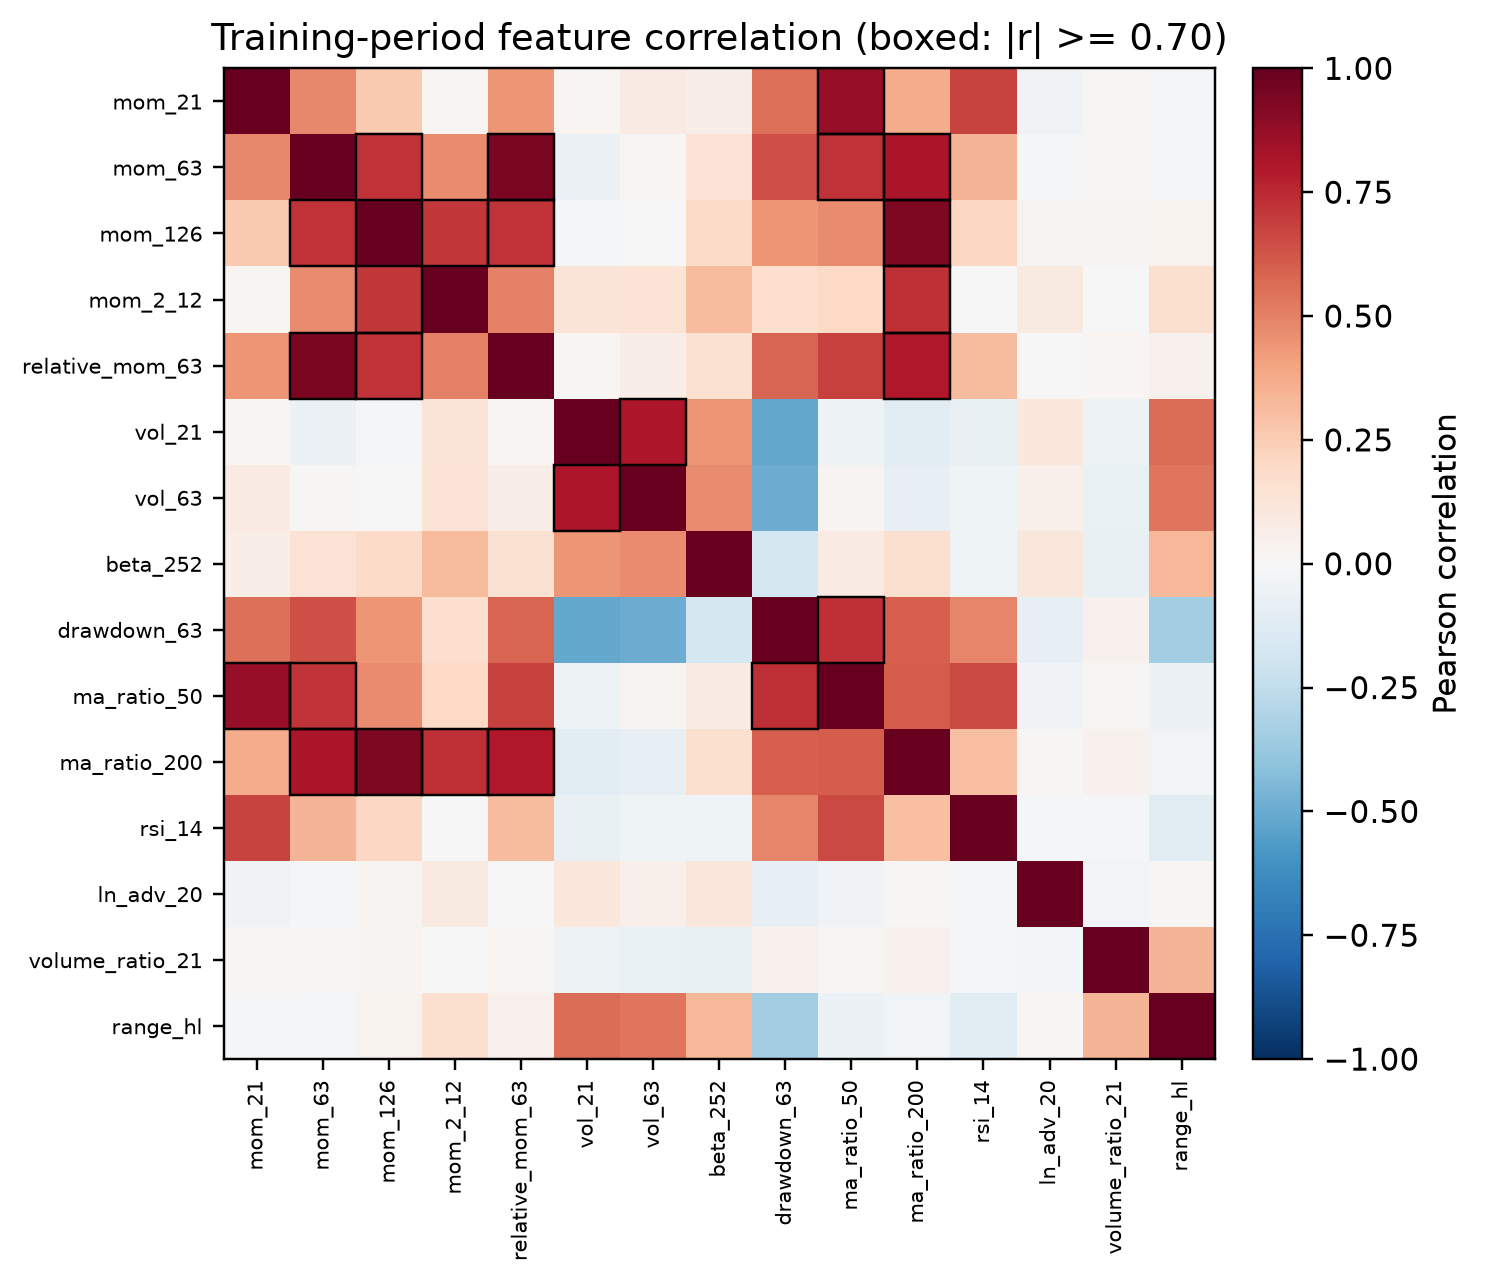

**coefficient trajectories**

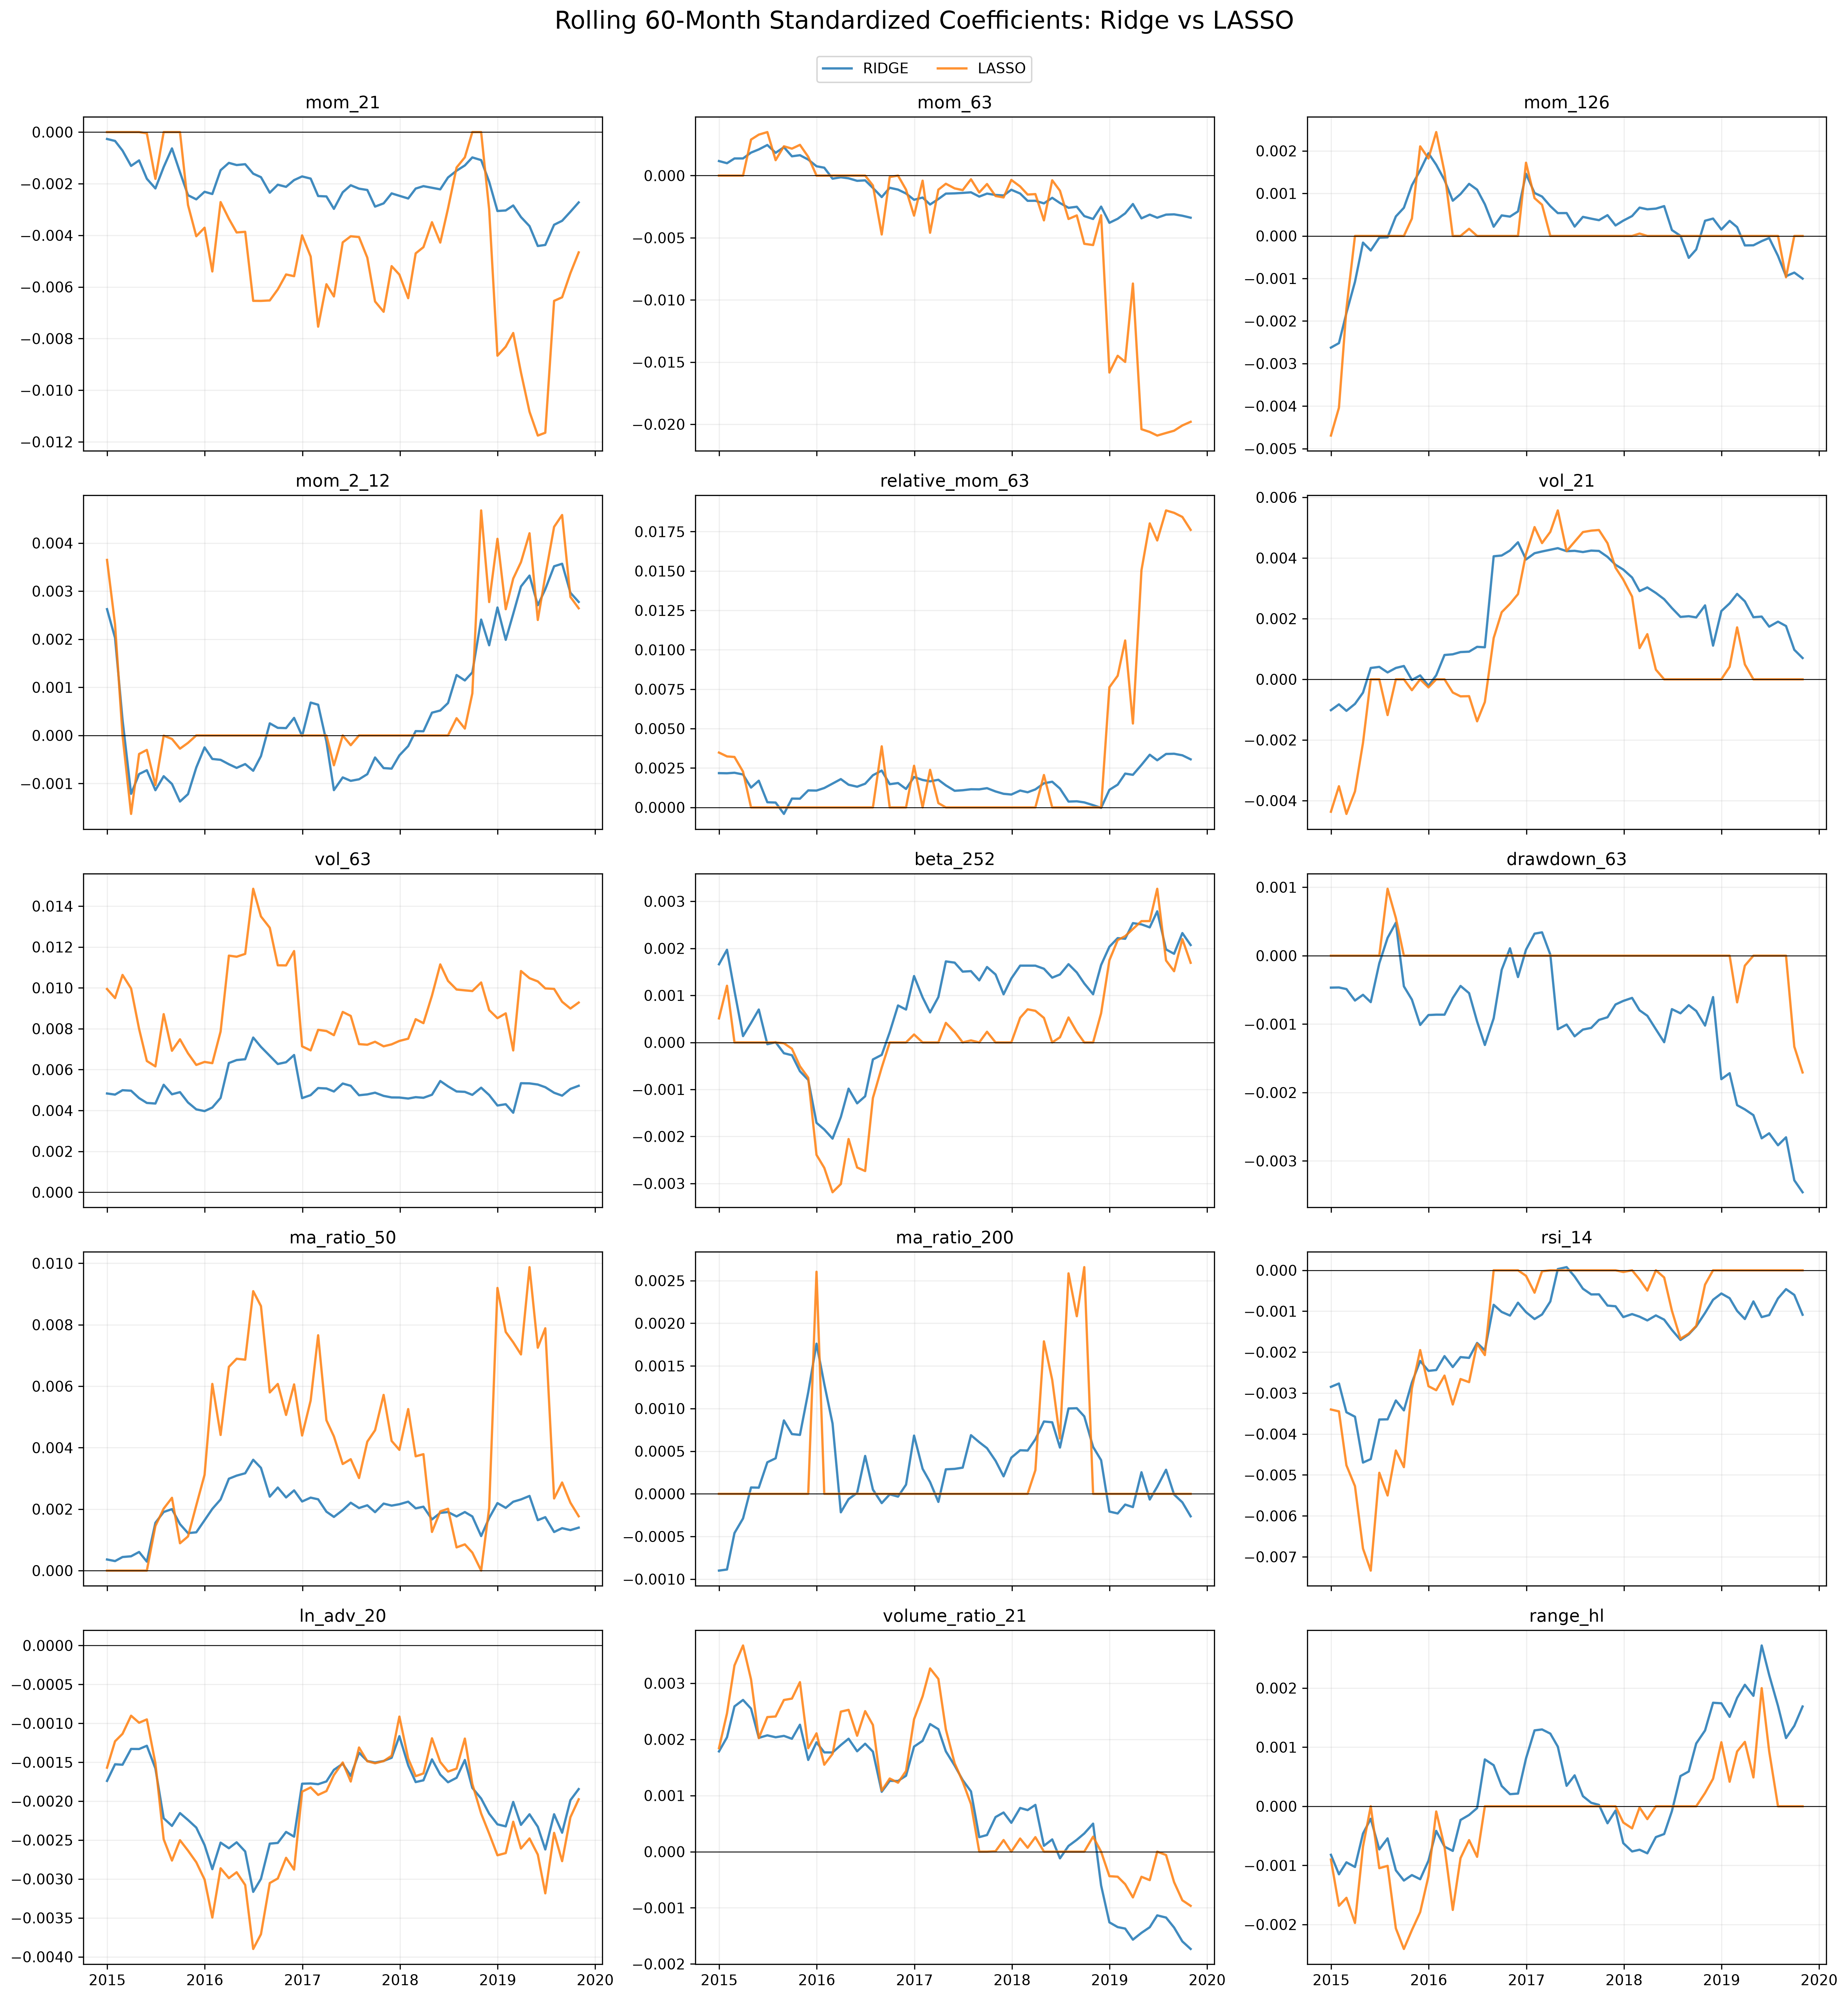

**report stability comparison**

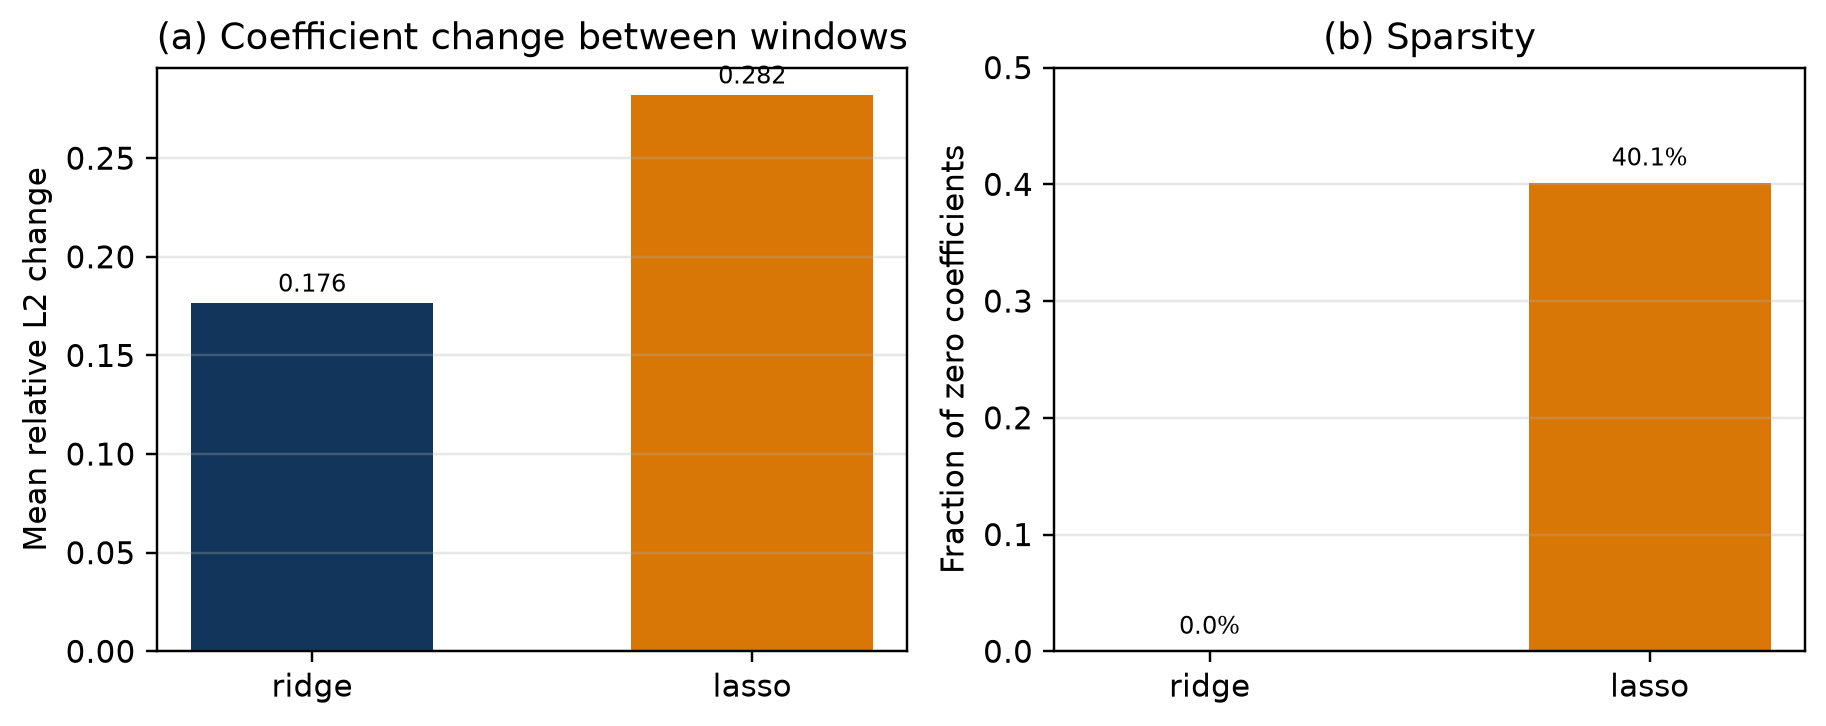

In [5]:
diagnostics = load_diagnostics(cfg)
diag_checks = validate_diagnostics(cfg, splits['train'])
make_report_figures(cfg)

summary = pd.DataFrame([
    ('Strongly correlated pairs (|r| >= 0.70)', diag_checks['n_strong_pairs_0_70']),
    ('Rolling windows analysed', diag_checks['n_windows']),
    ('Ridge mean relative coefficient change', f"{diag_checks['ridge_mean_relative_change']:.3f}"),
    ('LASSO mean relative coefficient change', f"{diag_checks['lasso_mean_relative_change']:.3f}"),
    ('Ridge reduction in relative change', f"{diag_checks['ridge_relative_change_reduction']:.1%}"),
    ('LASSO zero-coefficient fraction', f"{diag_checks['lasso_zero_fraction']:.1%}"),
    ('Ridge sign flips', diag_checks['ridge_sign_flips']),
    ('LASSO sign flips', diag_checks['lasso_sign_flips']),
    ('Correlation matrix reproduced from training slice', diag_checks['correlation_matches_training_slice']),
], columns=['Diagnostic', 'Value'])
display(summary)
display(strong_pairs_table(cfg))

for name in ['report_correlation_heatmap.png', 'coefficient_trajectories.png', 'report_stability_comparison.png']:
    path = resolve(cfg['paths']['research_diagnostics']) / name
    display(Markdown(f"**{name.replace('.png', '').replace('_', ' ')}**"))
    display(Image(filename=str(path), width=820))

The correlation heatmap shows two blocks. Momentum and trend features co-move strongly, and the volatility and range features form a second block. Liquidity is almost orthogonal to both. A sparse model is therefore likely to select one representative of each block and to discard the rest; a dense model keeps all horizons and lets the penalty allocate weight across them. Neither behaviour is universally superior, but the dense representation is a better match for a strategy that needs a stable cross-sectional ordering across many correlated signals.

## 6. Training, Validation and Hyperparameter Tuning

Hyperparameters are selected separately for each model on the validation period. The grid is small and fixed in advance: six Ridge penalties, five LASSO penalties, four Random Forest configurations and eight XGBoost configurations, twenty-three in total. Ridge and LASSO are fitted through a `StandardScaler` pipeline. Tree models use fixed seeds, shallow depth and minimum-leaf constraints.

| Model | Algorithm | Grid | Overfitting control |
|---|---|---|---|
| Ridge | Closed-form L2 regression | `alpha` ∈ {0.1, 1, 10, 100, 1000, 10000} | L2 penalty |
| LASSO | L1 coordinate descent | `alpha` ∈ {1e-5, 1e-4, 1e-3, 1e-2, 0.1} | L1 penalty, sparsity |
| Random Forest | Bagged regression trees | `max_depth` ∈ {3, 6}, `min_samples_leaf` ∈ {10, 25} | Shallow trees, bagging |
| XGBoost | Boosted regression trees | `max_depth` ∈ {2, 3}, `learning_rate` ∈ {0.03, 0.1}, `n_estimators` ∈ {100, 200} | Shrinkage, subsampling, L2 |

Training uses 2010–2019 with settled labels, validation uses 2020–2021 with settled labels, and the test period is untouched. Random seed 42 is used throughout. The exact package versions are printed in Section 14.

In [6]:
search_rows = []
for name in MODEL_NAMES:
    grid = parameter_grid(name, cfg['models'][name])
    search_rows.append({'model': MODEL_LABELS[name], 'configurations': len(grid), 'grid': json.dumps(cfg['models'][name]['grid'], sort_keys=True)})
grid_table = pd.DataFrame(search_rows)
display(grid_table)
print('Total configurations:', int(grid_table.configurations.sum()))

validation_result = run_validation(cfg)
search = validation_result['search']
display(search.loc[search.selected][[
    'model', 'params', 'train_mse', 'validation_mse', 'validation_mae',
    'validation_r2_sklearn', 'convergence_n_iter', 'convergence_n_nonzero_features', 'convergence_converged',
]].sort_values('validation_mse'))

,model,configurations,grid
0,Ridge Regression,6,"{""alpha"": [0.1, 1.0, 10.0, 100.0, 1000.0, 1000..."
1,LASSO Regression,5,"{""alpha"": [1e-05, 0.0001, 0.001, 0.01, 0.1]}"
2,Random Forest,4,"{""max_depth"": [3, 6], ""min_samples_leaf"": [10,..."
3,XGBoost,8,"{""learning_rate"": [0.03, 0.1], ""max_depth"": [2..."


Total configurations: 23


,model,params,train_mse,validation_mse,validation_mae,validation_r2_sklearn,convergence_n_iter,convergence_n_nonzero_features,convergence_converged
2,lasso,"{""alpha"": 0.001}",0.007344,0.022281,0.090963,0.045059,17.0,9.0,True
6,rf,"{""max_depth"": 3, ""min_samples_leaf"": 25}",0.007120,0.022412,0.091106,0.039453,NaN,NaN,NaN
13,ridge,"{""alpha"": 1000.0}",0.007333,0.022422,0.091106,0.039047,NaN,15.0,NaN
15,xgb,"{""learning_rate"": 0.03, ""max_depth"": 2, ""n_est...",0.007016,0.022642,0.091654,0.029618,NaN,NaN,NaN


## 7. Four-Model Validation Comparison

The validation comparison asks two different questions. Prediction metrics measure average forecast accuracy across all thirty candidates. Portfolio metrics measure what a Top-10 strategy would have earned after costs. They need not agree, because the portfolio uses only the ordering of the highest scores.

Two \(R^2\) definitions are reported. Ordinary sklearn \(R^2\) uses the validation sample mean as the benchmark and is descriptive. The benchmark-relative OOS \(R^2\) uses the training mean, which was available in real time, and therefore answers whether the model beats a naive historical-mean forecast. Directional accuracy is reported on raw signs and on cross-sectionally demeaned signs; the second is closer to the ranking decision the strategy actually makes. Rank IC is the within-month Spearman correlation between predictions and realised returns.

**Superseded auxiliary artifact.** An earlier engineering revision added an automatic `lowest_validation_mse` rule, which selected LASSO. That rule was a coding convenience, not the research team's model-assessment policy, and it has been removed from the active workflow. Its output is retained for audit only under `results/validation/archive/superseded_automatic_selection/` and is labelled as superseded. The primary model is Ridge, designated below on economic and diagnostic grounds.

**Primary-model policy.** The model assessment is based on economic considerations and validation-stage evidence; out-of-sample performance is reported separately and is not used as a numerical model-selection criterion. The research design designates Ridge as the primary model. The designation rests on the economic argument in Section 5, on Ridge's higher validation Rank IC, and on its lower relative coefficient movement. Ridge's hyperparameter, `alpha = 1000`, is still chosen by validation MSE *within* Ridge; no test-period information enters the choice. The policy is recorded in `primary_model_contract.json`, which also records that the project history includes prior OOS review and that the designation is therefore not a clean pre-registration.

This distinction is the point of Section 4.7 of the assignment: a small pre-declared grid, a time-respecting validation, and one clear selection rule. The rule here is an explicit research-design rule, not a numerical minimisation across models.

In [7]:
comparison = validation_result['comparison'].copy()
display(comparison[[
    'model', 'validation_mse', 'validation_rmse', 'validation_r2_sklearn',
    'validation_r2_oos_trainmean', 'directional_accuracy', 'directional_accuracy_cs',
    'validation_mean_rank_ic', 'validation_sharpe', 'validation_cagr',
    'validation_max_drawdown',
]].round(5))

# Read-only audit of the superseded automatic rule. It is not used to define the primary model.
archive_dir = resolve(cfg['paths']['validation']) / 'archive' / 'superseded_automatic_selection'
historical_summary = pd.read_csv(archive_dir / 'model_selection_summary.csv')
display(historical_summary[['model', 'validation_mse', 'validation_sharpe', 'selection_rank', 'selected', 'selection_criterion']])
print('Status: superseded auxiliary artifact; excluded from the active workflow.')
print('Archived contract:', (archive_dir / 'selection_contract.json').relative_to(PROJECT_ROOT))

,model,validation_mse,validation_rmse,validation_r2_sklearn,validation_r2_oos_trainmean,directional_accuracy,directional_accuracy_cs,validation_mean_rank_ic,validation_sharpe,validation_cagr,validation_max_drawdown
0,lasso,0.02228,0.14927,0.04506,0.04951,0.57424,0.54697,0.02496,0.92631,0.46138,-0.30034
1,rf,0.02241,0.14971,0.03945,0.04393,0.56970,0.54848,0.02612,0.86594,0.40196,-0.33226
2,ridge,0.02242,0.14974,0.03905,0.04352,0.57727,0.54697,0.04377,0.91774,0.45690,-0.31714
3,xgb,0.02264,0.15047,0.02962,0.03414,0.56364,0.53636,-0.00984,0.69318,0.26590,-0.29159


,model,validation_mse,validation_sharpe,selection_rank,selected,selection_criterion
0,lasso,0.022281,0.926312,1,True,lowest_validation_mse
1,rf,0.022412,0.865945,2,False,lowest_validation_mse
2,ridge,0.022422,0.917743,3,False,lowest_validation_mse
3,xgb,0.022642,0.693179,4,False,lowest_validation_mse


Status: superseded auxiliary artifact; excluded from the active workflow.
Archived contract: results/validation/archive/superseded_automatic_selection/selection_contract.json


In [8]:
APPROVE_PRIMARY_DESIGNATION = True

if APPROVE_PRIMARY_DESIGNATION:
    primary_contract = designate_primary_model(
        cfg,
        approve=True,
        note='Ridge designated on economic and diagnostic grounds; alpha chosen by validation MSE within Ridge.',
    )
else:
    primary_contract = None
    print('Set APPROVE_PRIMARY_DESIGNATION = True to freeze the Ridge designation.')

assert primary_contract is not None
display(designation_table(cfg)[[
    'model', 'research_role', 'validation_mse', 'validation_mean_rank_ic',
    'validation_sharpe', 'validation_cagr', 'is_primary',
]].round(5))

print('Primary model          :', primary_contract['primary_model'])
print('Hyperparameters        :', primary_contract['selected_hyperparameters'])
print('Hyperparameter rule    :', primary_contract['hyperparameter_rule'])
print('Test used for selection:', primary_contract['test_used_for_selection'])
print('Clean pre-registration :', primary_contract['clean_preregistration'])
print('Prior OOS review       :', primary_contract['designation_informed_by_prior_oos_review'])

,model,research_role,validation_mse,validation_mean_rank_ic,validation_sharpe,validation_cagr,is_primary
0,lasso,Alternative model,0.02228,0.02496,0.92631,0.46138,False
1,rf,Alternative model,0.02241,0.02612,0.86594,0.40196,False
2,ridge,Primary research model,0.02242,0.04377,0.91774,0.45690,True
3,xgb,Alternative model,0.02264,-0.00984,0.69318,0.26590,False


Primary model          : ridge
Hyperparameters        : {'alpha': 1000.0}
Hyperparameter rule    : lowest_validation_mse_within_ridge
Test used for selection: False
Clean pre-registration : False
Prior OOS review       : True


**Why Ridge despite a lower validation MSE than LASSO?** Three reasons, in order of importance. First, the object the portfolio needs is a cross-sectional ordering, not a calibrated conditional mean. Ridge has the highest validation Rank IC of the four models, which is the metric most closely aligned with that ordering, even though LASSO has a marginally lower MSE. Second, the predictors are strongly correlated; an L2 penalty keeps all horizons and shrinks their combined influence, whereas an L1 penalty selects one representative per correlated block and discards the rest. Third, the rolling-window diagnostics show materially lower relative coefficient movement for Ridge. This does not make Ridge uniformly better: LASSO has the lower validation MSE and the slightly higher validation Sharpe, and Ridge's coefficients sign-flip more often. The designation is a research-design judgment, not a claim that Ridge dominates on every metric.

## 8. Primary Ridge Strategy and Trading Rules

The primary strategy is fixed as follows.

1. At the month-end decision close, apply the original eligibility filters and ADV20 Top-300 ranking.
2. Apply the 3×3 momentum × volatility double sort to obtain thirty candidates.
3. Score all thirty with the refitted Ridge model.
4. Rank by predicted return (descending, ticker ascending for ties) and buy the Top 10.
5. Assign equal 10% target weights; the portfolio is fully invested with no cash and no leverage.
6. Execute at the next session open. Rebalance monthly.
7. Charge 20 basis points on each traded side, applied to the sum of absolute weight changes against drifted pre-trade weights. Remaining holdings are not liquidated and repurchased.

The model is refitted once on all eligible 2010–2021 observations whose labels settle by 2021-12-31, using the validation-selected `alpha`. The same frozen model is used through the 2022–2025 test period; there is no rolling retraining.

This is distinct from the exploratory strategies in Section 12. In particular, **R1 RidgeWeighted10** uses momentum Top-10 selection with Ridge-prediction-proportional weights capped at 20% and is not the primary strategy.

In [9]:
refit_result = refit_models(cfg, contract=primary_contract)
display(refit_result['summary'][[
    'model', 'is_selected', 'hyperparameters', 'n_training_observations',
    'refit_decision_start', 'refit_decision_end', 'refit_label_end_max', 'random_seed',
]])
metadata = refit_result['metadata']
print('Refit rows:', metadata['n_training_observations'],
      '| features:', metadata['n_features'],
      '| test accessed:', metadata['test_data_accessed'])

,model,is_selected,hyperparameters,n_training_observations,refit_decision_start,refit_decision_end,refit_label_end_max,random_seed
0,ridge,True,"{""alpha"": 1000.0}",4260,2010-01-29,2021-10-29,2021-12-01,42
1,lasso,False,"{""alpha"": 0.001}",4260,2010-01-29,2021-10-29,2021-12-01,42
2,rf,False,"{""max_depth"": 3, ""min_samples_leaf"": 25}",4260,2010-01-29,2021-10-29,2021-12-01,42
3,xgb,False,"{""learning_rate"": 0.03, ""max_depth"": 2, ""n_est...",4260,2010-01-29,2021-10-29,2021-12-01,42


Refit rows: 4260 | features: 15 | test accessed: False


### 8.1 From scores to positions: a real example

The equal-weight rule uses the predicted return only to rank candidates. The score does not scale the position: every selected stock receives the same 10% target weight.

\[
w_{i,t} =
\begin{cases}
0.1, & i \in \operatorname{Top10}(\hat r_{i,t+1}),\\
0, & \text{otherwise}.
\end{cases}
\]

Figure 1 shows one actual decision date from the saved out-of-sample predictions, 30 June 2025. The thirty candidates are ordered by Ridge predicted return; the top ten receive 10% weights and the remaining twenty receive zero. No illustrative scores are used.

,rank,ticker,prediction,selected,target_weight,mom_2_12
0,1,APP,0.087587,True,0.1,3.722422
1,2,PLTR,0.066313,True,0.1,4.202527
2,3,REGN,0.042537,True,0.1,-0.532235
3,4,SMCI,0.036468,True,0.1,-0.511564
4,5,TER,0.029109,True,0.1,-0.467492
5,6,HOOD,0.026581,True,0.1,1.912814
6,7,BA,0.025084,True,0.1,0.139058
7,8,LYB,0.024738,True,0.1,-0.380820
8,9,OXY,0.024126,True,0.1,-0.343987
9,10,TGT,0.019650,True,0.1,-0.342445


Selected: 10 | weight sum: 1.0


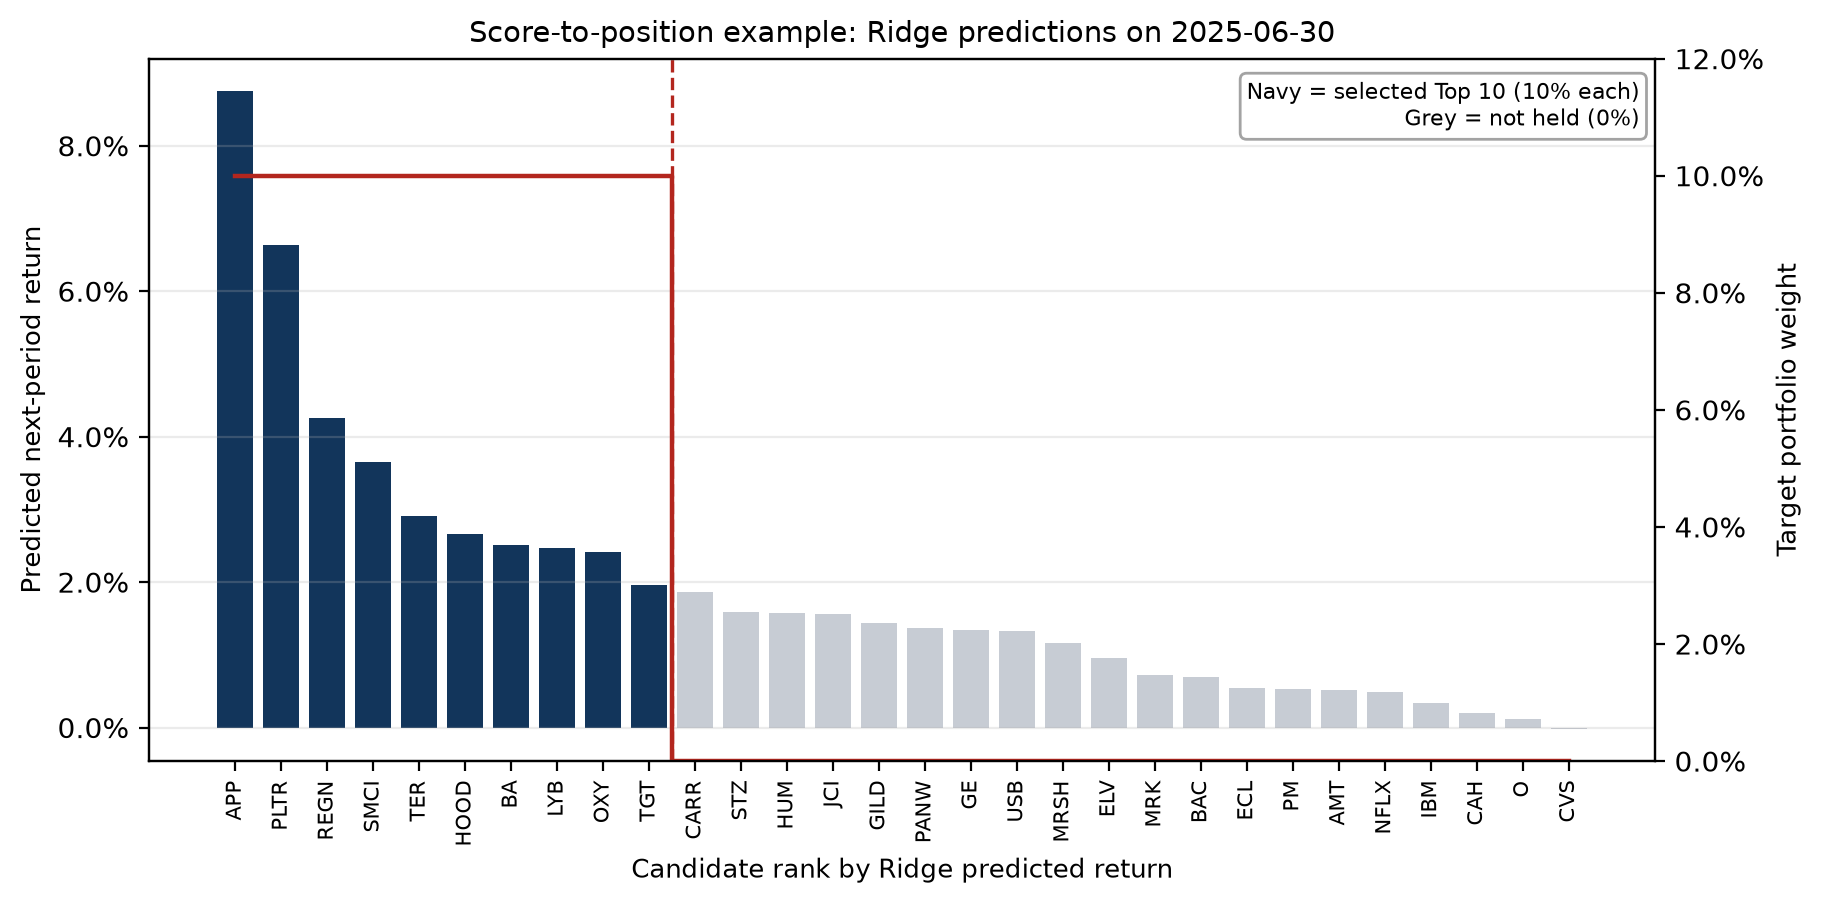

In [10]:
score_result = run_score_position_example(cfg, decision_date='2025-06-30')
display(score_result['table'][[
    'rank', 'ticker', 'prediction', 'selected', 'target_weight', 'mom_2_12',
]].head(12).round(6))
print('Selected:', int(score_result['table'].selected.sum()),
      '| weight sum:', float(score_result['table'].target_weight.sum()))
display(Image(filename=str(resolve(cfg['paths']['oos_figures']) / 'fig_score_to_position.png'), width=900))

## 9. Final OOS Evaluation: Four ML Models

The test period is opened once for evaluation, after the model and hyperparameters are fixed using training and validation information. Predictions are generated with the refitted models and converted into positions with the unchanged Top-10 equal-weight rules. The benchmark-relative OOS \(R^2\) uses the historical mean of the refit sample.

All four models are reported. The four-model comparison is descriptive rather than a second model-selection step; the primary model remains Ridge regardless of the outcome.

,model,is_selected,test_rows,test_dates,mse,rmse,mae,r2_sklearn,r2_oos_trainmean,directional_accuracy,directional_accuracy_cs,mean_rank_ic
0,ridge,True,1440,48,0.01506,0.12271,0.08280,0.01868,0.01868,0.52917,0.54375,0.06195
1,lasso,False,1440,48,0.01509,0.12285,0.08296,0.01641,0.01641,0.53264,0.53472,0.06022
2,rf,False,1440,48,0.01529,0.12367,0.08340,0.00326,0.00326,0.54931,0.53611,0.08784
3,xgb,False,1440,48,0.01518,0.12321,0.08299,0.01060,0.01060,0.55000,0.53056,0.05745


,strategy,annualized_return,annualized_volatility,sharpe_ratio,sortino_ratio,max_drawdown,calmar_ratio,average_turnover,total_transaction_cost,benchmark_relative_annualized_return,information_ratio
0,ridge,0.4304,0.3256,1.2723,2.4068,-0.2854,1.5083,1.2578,0.1207,0.3033,1.2279
1,lasso,0.4215,0.3233,1.2595,2.3747,-0.2822,1.4936,1.2863,0.1235,0.2943,1.2266
2,rf,0.3998,0.3281,1.1977,2.2053,-0.2904,1.3767,1.2545,0.1204,0.2726,1.1104
3,xgb,0.3846,0.3083,1.2192,2.2563,-0.2707,1.4208,1.3186,0.1266,0.2574,1.1116


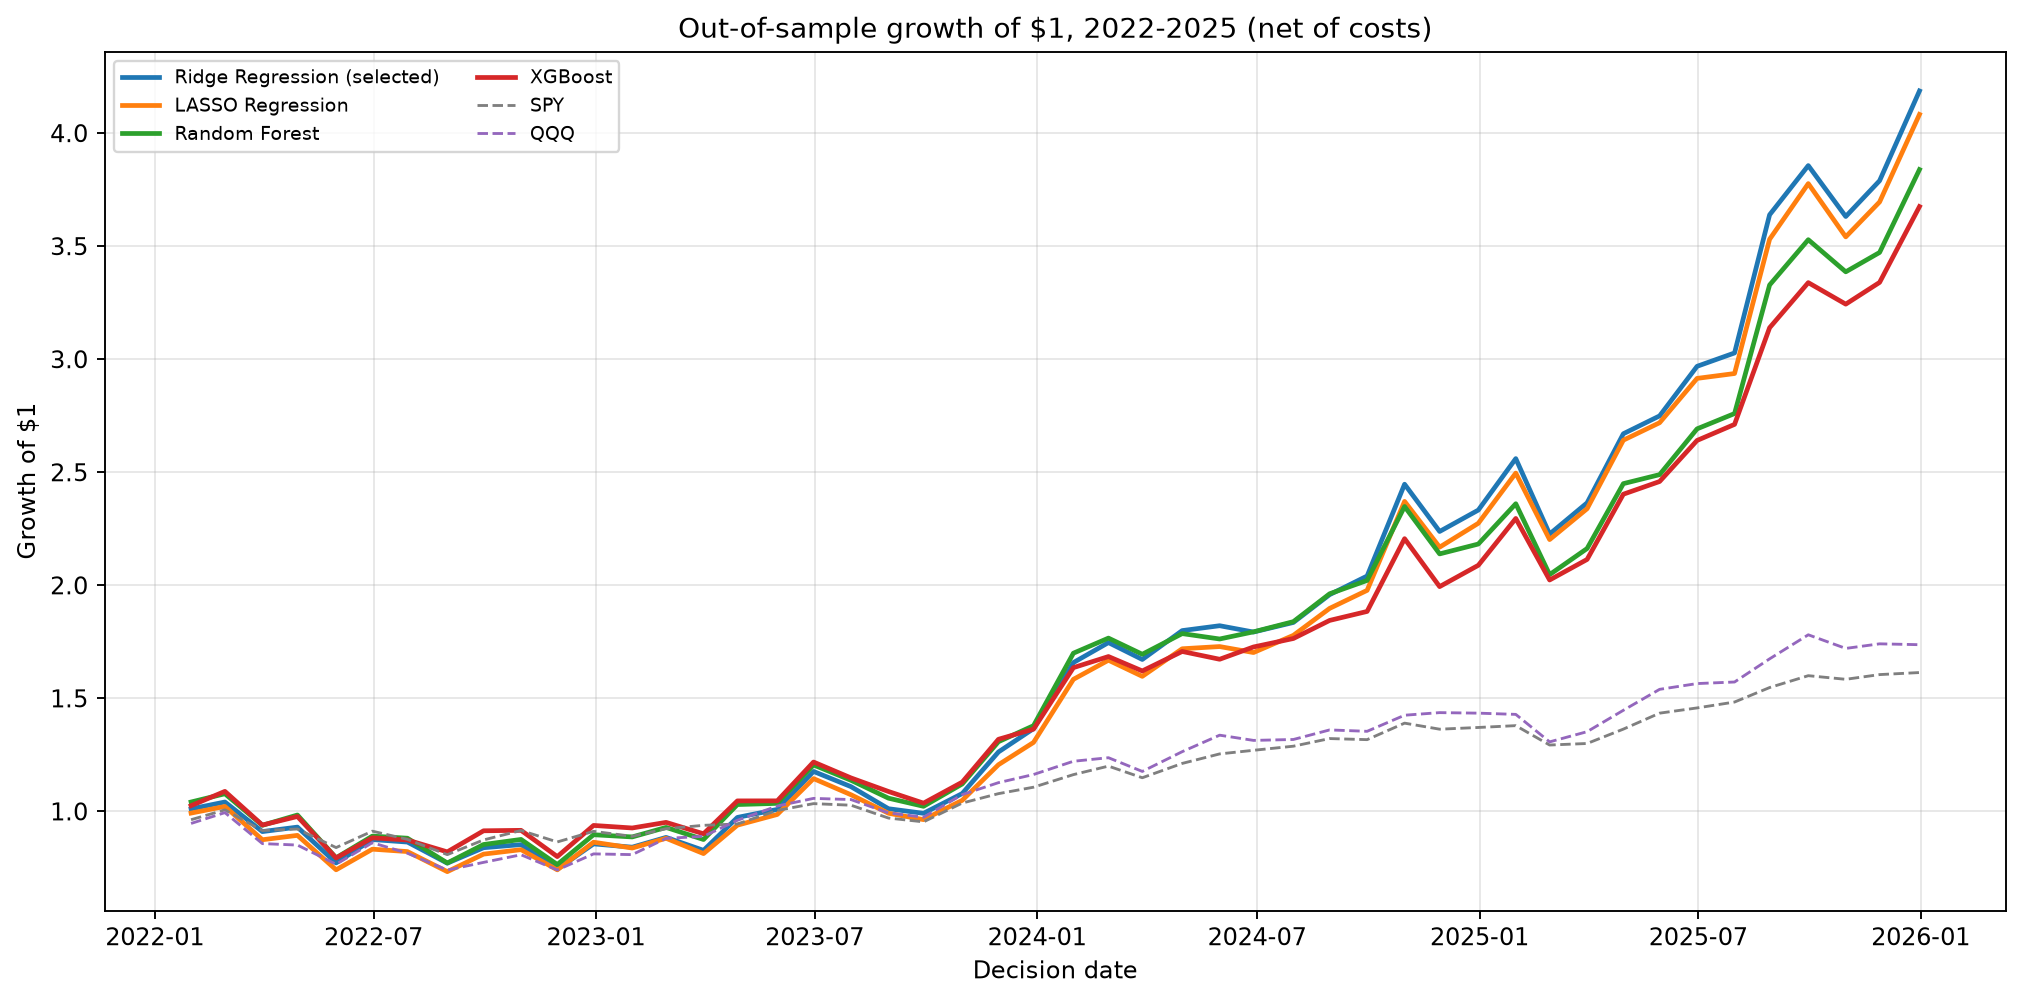

In [11]:
oos_result = run_oos(cfg, contract=primary_contract)
oos_prediction = oos_result['prediction_metrics'].copy()
display(oos_prediction[[
    'model', 'is_selected', 'test_rows', 'test_dates', 'mse', 'rmse', 'mae',
    'r2_sklearn', 'r2_oos_trainmean', 'directional_accuracy', 'directional_accuracy_cs', 'mean_rank_ic',
]].round(5))

oos_portfolio = oos_result['portfolio_metrics'].copy()
display(oos_portfolio[oos_portfolio.strategy.isin(MODEL_NAMES)][[
    'strategy', 'annualized_return', 'annualized_volatility', 'sharpe_ratio',
    'sortino_ratio', 'max_drawdown', 'calmar_ratio', 'average_turnover',
    'total_transaction_cost', 'benchmark_relative_annualized_return', 'information_ratio',
]].round(4))

for name in ['01_oos_cumulative_wealth.png']:
    display(Image(filename=str(resolve(cfg['paths']['oos_figures']) / name), width=900))

**Figure 1** (the four-model wealth chart above) shows the four ML models under the same trading rule. The ordering is tight for most of the period and widens after 2024. Ridge finishes with the highest terminal wealth and Sharpe among the four, although Random Forest has a higher OOS rank IC. The difference from LASSO is marginal: OOS MSE 0.015057 versus 0.015091, CAGR 43.0% versus 42.1%, and Sharpe 1.27 versus 1.26. These differences are not tested for statistical significance and do not establish universal superiority of Ridge. The figure should not be read as a decisive ranking: the models share the same candidates, features and costs, so the differences isolate the forecasting algorithm, and a four-year window is a short sample for distinguishing algorithms with similar signal-to-noise ratios.

## 10. Final OOS Evaluation: Ridge vs B1, B3, SPY and QQQ

The primary comparison adds two momentum baselines and two investable benchmarks.

- **Ridge vs B3** isolates the ranking method. Both use the same thirty candidates, the same monthly execution and the same costs. The only difference is whether the Top 10 is chosen by Ridge prediction or by twelve-month momentum.
- **Ridge vs B1** changes two things at once: B1 selects from the full liquid Top-300 rather than the 3×3 pool, and it ranks by momentum. It is therefore a comparison of complete strategies, not a clean ranking test.
- **Ridge vs SPY and QQQ** asks whether the active strategy beats a buy-and-hold investor after costs. SPY and QQQ bear a single entry cost and no monthly rebalancing cost.

The main experiment and the extension were produced by different drivers. The comparison below reconciles them on the same 48 decision dates, verifies that SPY and QQQ returns are identical across engines, and verifies date by date that B3 is the momentum Top-10 of the same thirty-candidate pool. No strategy rule is altered.

In [12]:
extension_result = run_ridge_extension(cfg)
eight_result = run_eight_strategy_comparison(cfg)
panel = eight_result['panel']
metrics8 = eight_result['metrics']
checks = eight_result['checks']

display(metrics8[[
    'strategy', 'role', 'annualized_return', 'annualized_return_gross', 'annualized_volatility',
    'sharpe_ratio', 'sortino_ratio', 'max_drawdown', 'calmar_ratio',
    'average_turnover', 'total_transaction_cost', 'benchmark_relative_annualized_return',
]].round(4))
print('Alignment:', {k: checks[k] for k in ['decision_dates_identical', 'benchmarks_identical', 'b3_rule_verified', 'periods_per_strategy']})

,strategy,role,annualized_return,annualized_return_gross,annualized_volatility,sharpe_ratio,sortino_ratio,max_drawdown,calmar_ratio,average_turnover,total_transaction_cost,benchmark_relative_annualized_return
0,ridge,ML model (primary),0.4304,0.4730,0.3256,1.2723,2.4068,-0.2854,1.5083,1.2578,0.1207,0.3033
1,lasso,ML model (alternative),0.4215,0.4649,0.3233,1.2595,2.3747,-0.2822,1.4936,1.2863,0.1235,0.2943
2,rf,ML model (alternative),0.3998,0.4414,0.3281,1.1977,2.2053,-0.2904,1.3767,1.2545,0.1204,0.2726
3,xgb,ML model (alternative),0.3846,0.4280,0.3083,1.2192,2.2563,-0.2707,1.4208,1.3186,0.1266,0.2574
4,B1_Momentum10,Momentum baseline,0.7313,0.7574,0.3772,1.6638,3.8553,-0.1919,3.8108,0.6504,0.0624,0.6041
5,B3_MomentumDoubleSort10,Momentum baseline,0.5151,0.5483,0.2904,1.5904,3.6754,-0.1499,3.4368,0.9382,0.0901,0.3879
6,SPY,Investable benchmark,0.1272,0.1278,0.1527,0.8632,1.3464,-0.1967,0.6464,0.0208,0.0020,0.0000
7,QQQ,Investable benchmark,0.1481,0.1487,0.1993,0.7955,1.2464,-0.2556,0.5793,0.0208,0.0020,0.0209


Alignment: {'decision_dates_identical': True, 'benchmarks_identical': True, 'b3_rule_verified': True, 'periods_per_strategy': 48}


**Figure 1. Four ML models under the common trading rule.**

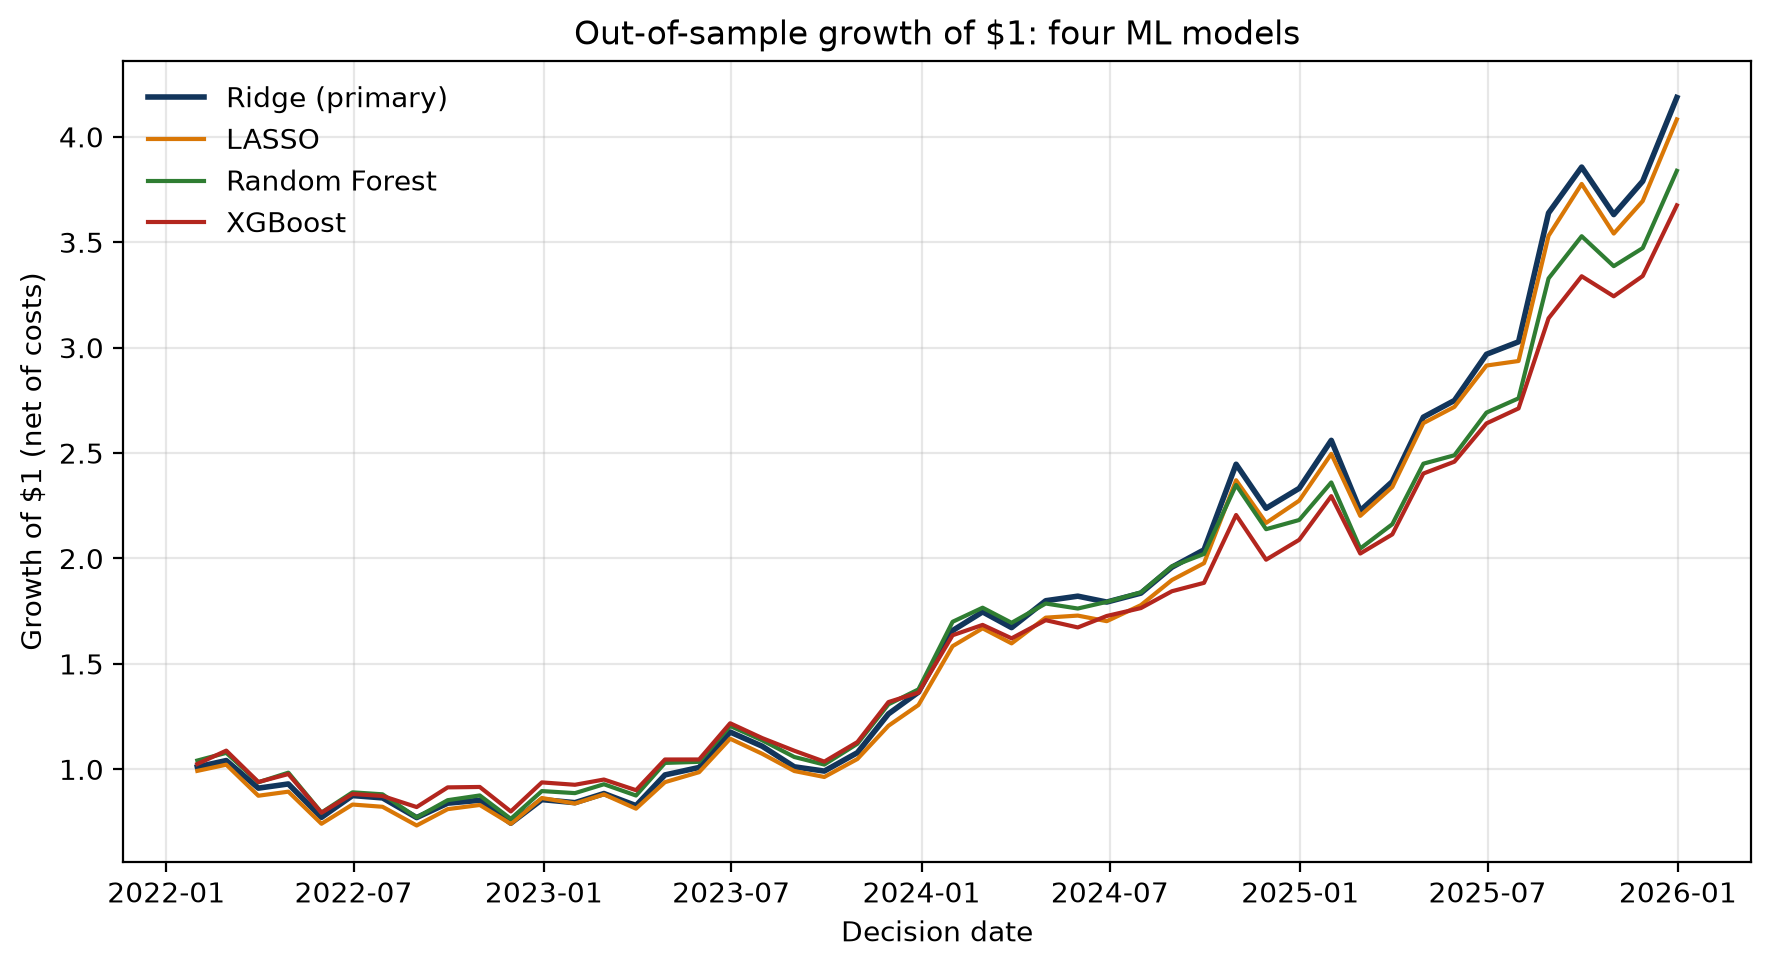

**Figure 2. Primary Ridge vs B1, B3, SPY and QQQ.**

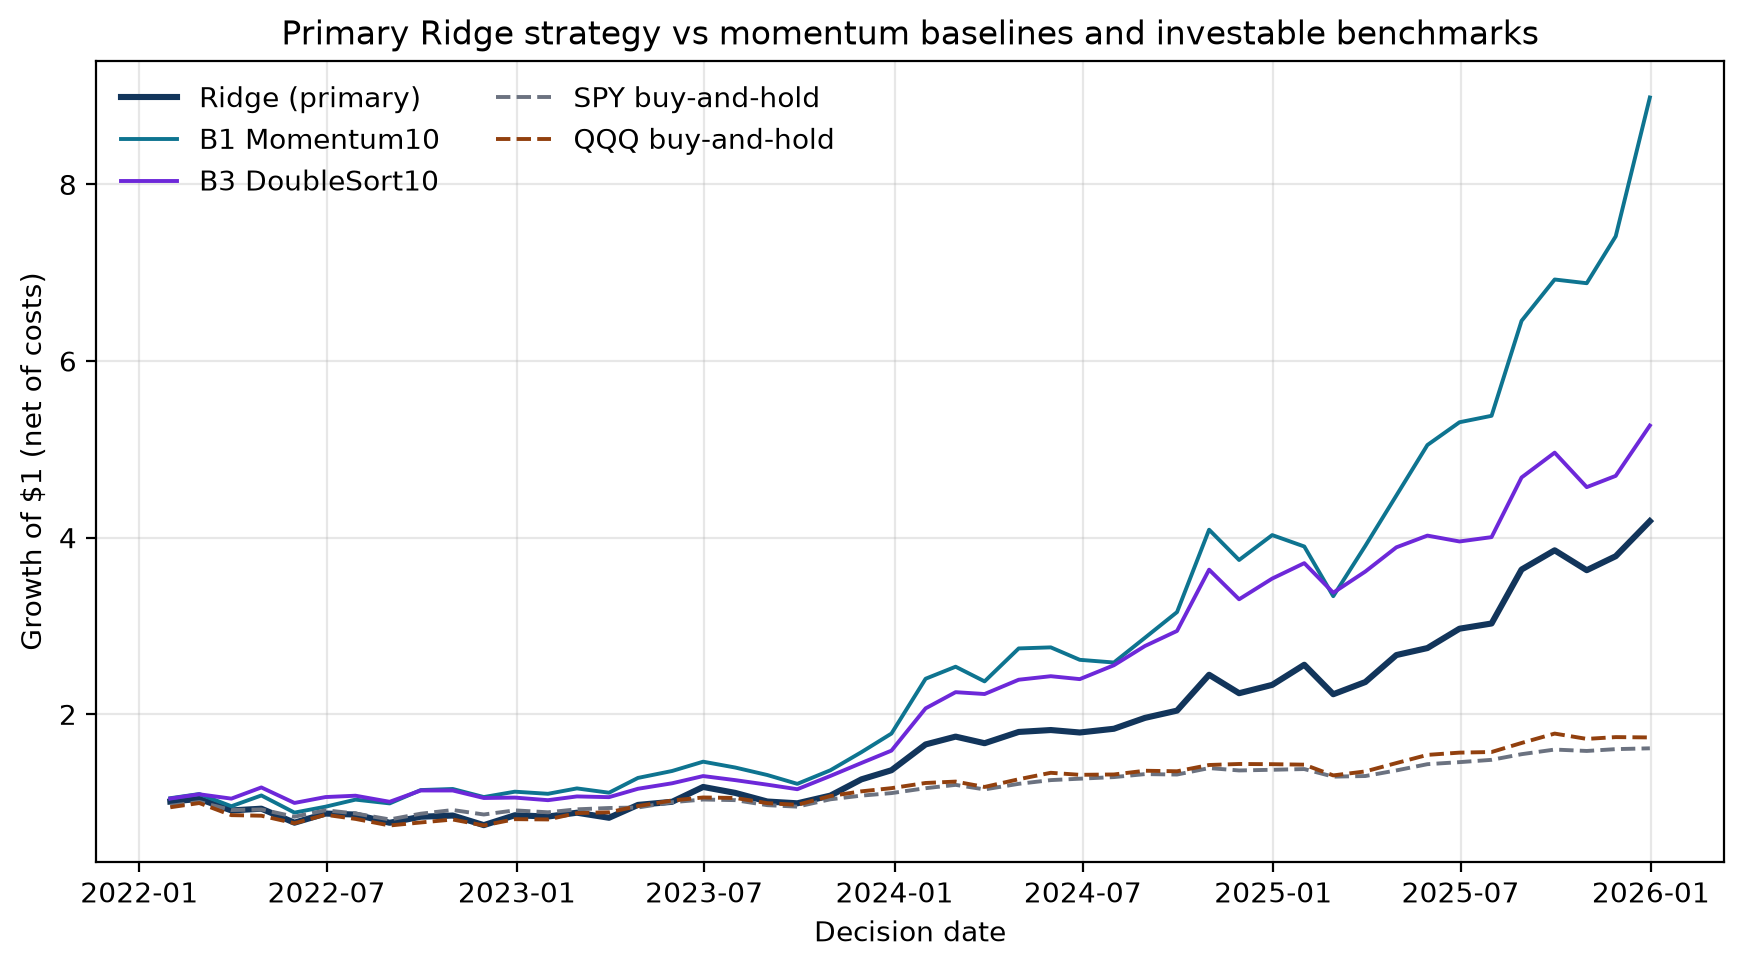

**Figure 3. Eight-strategy summary: CAGR and Sharpe.**

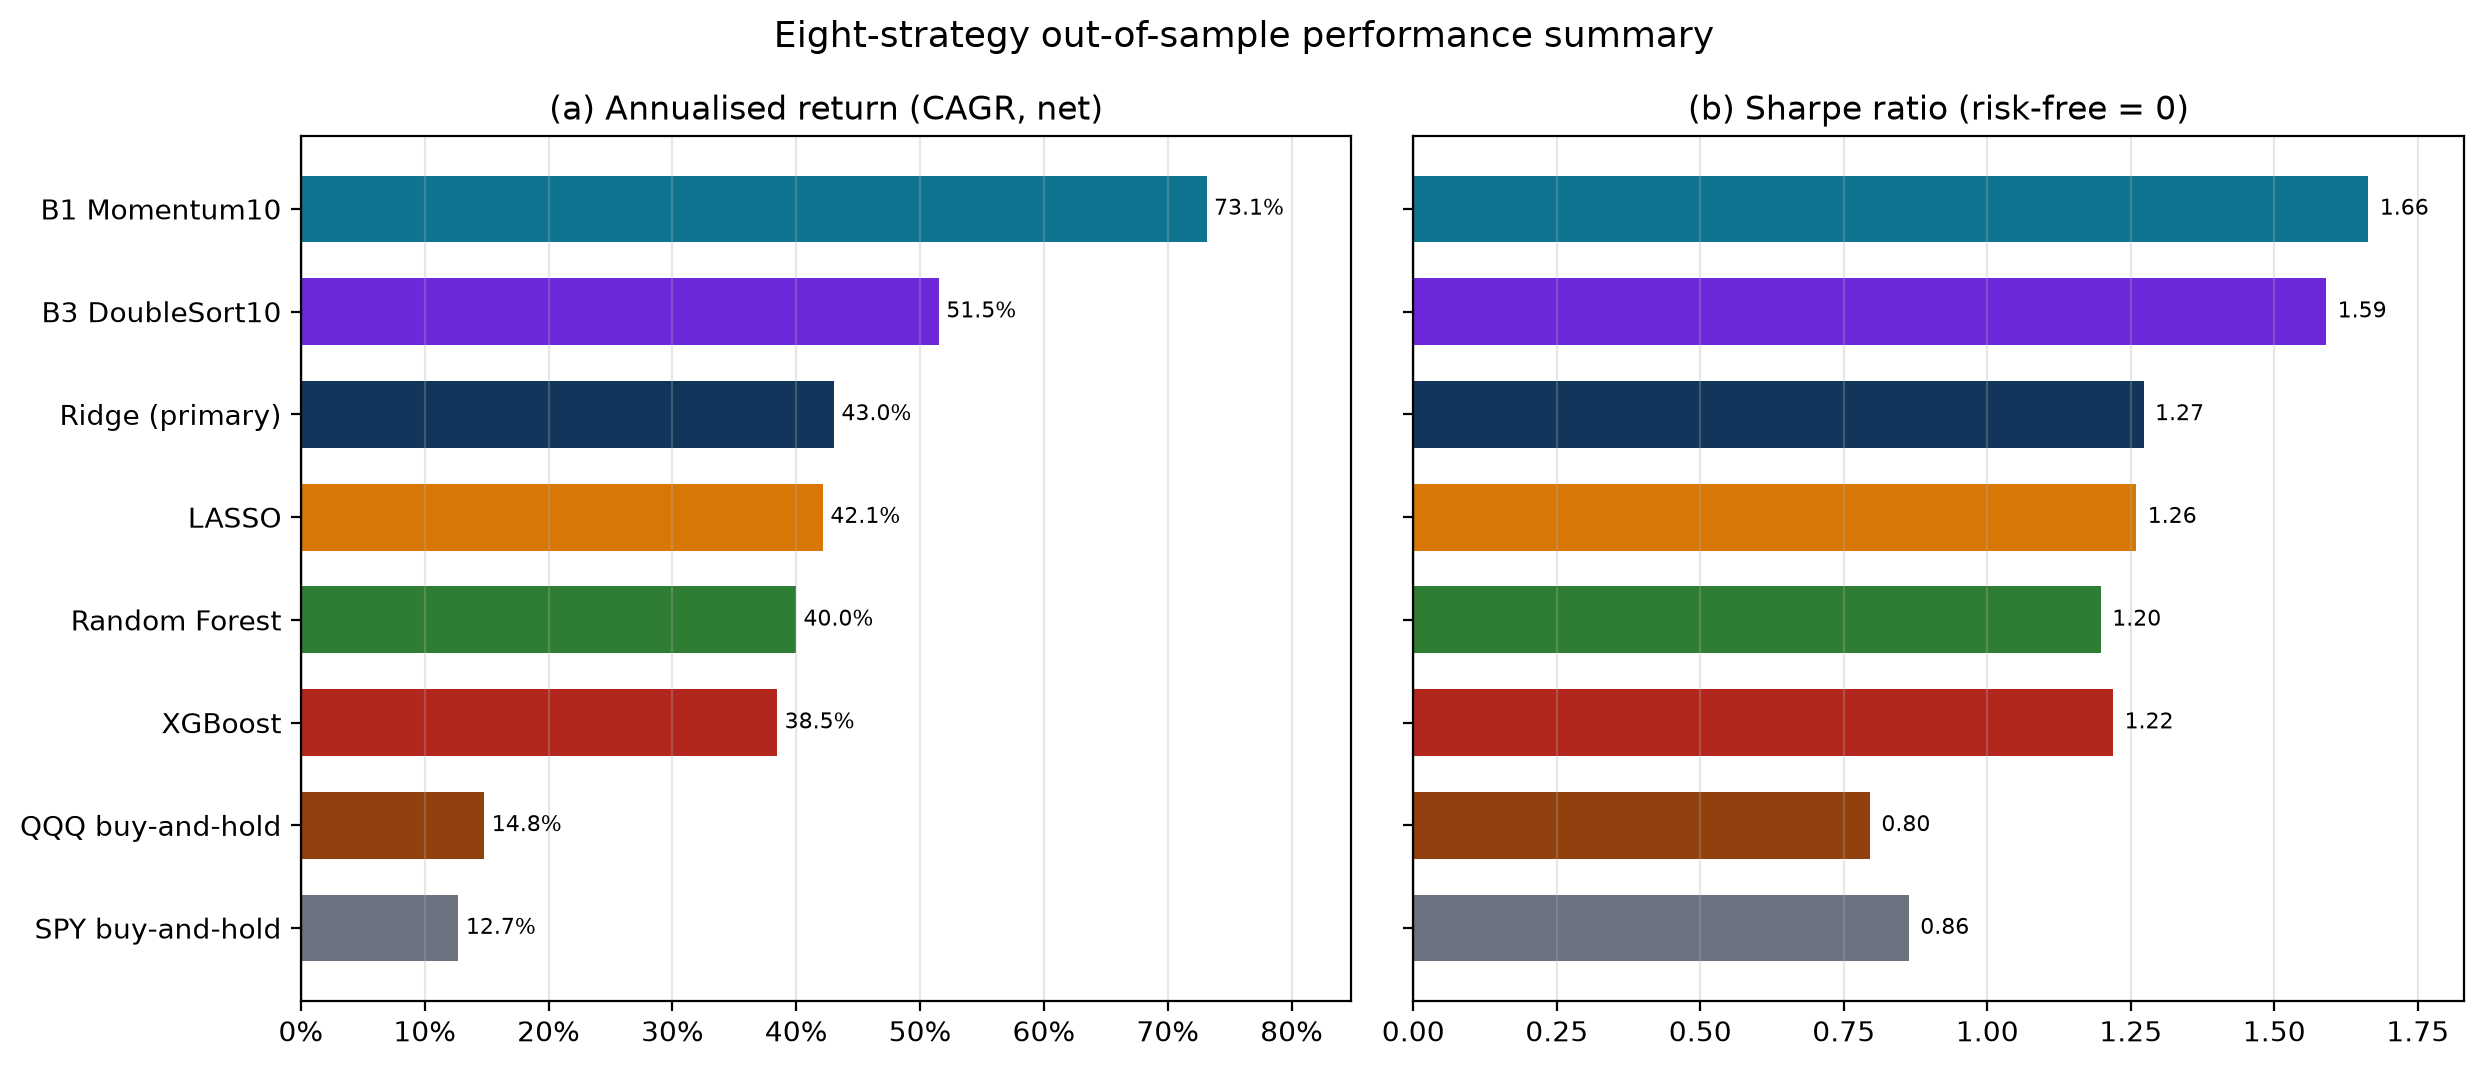

**Figure 4. Drawdowns: Ridge, B1, B3, SPY and QQQ.**

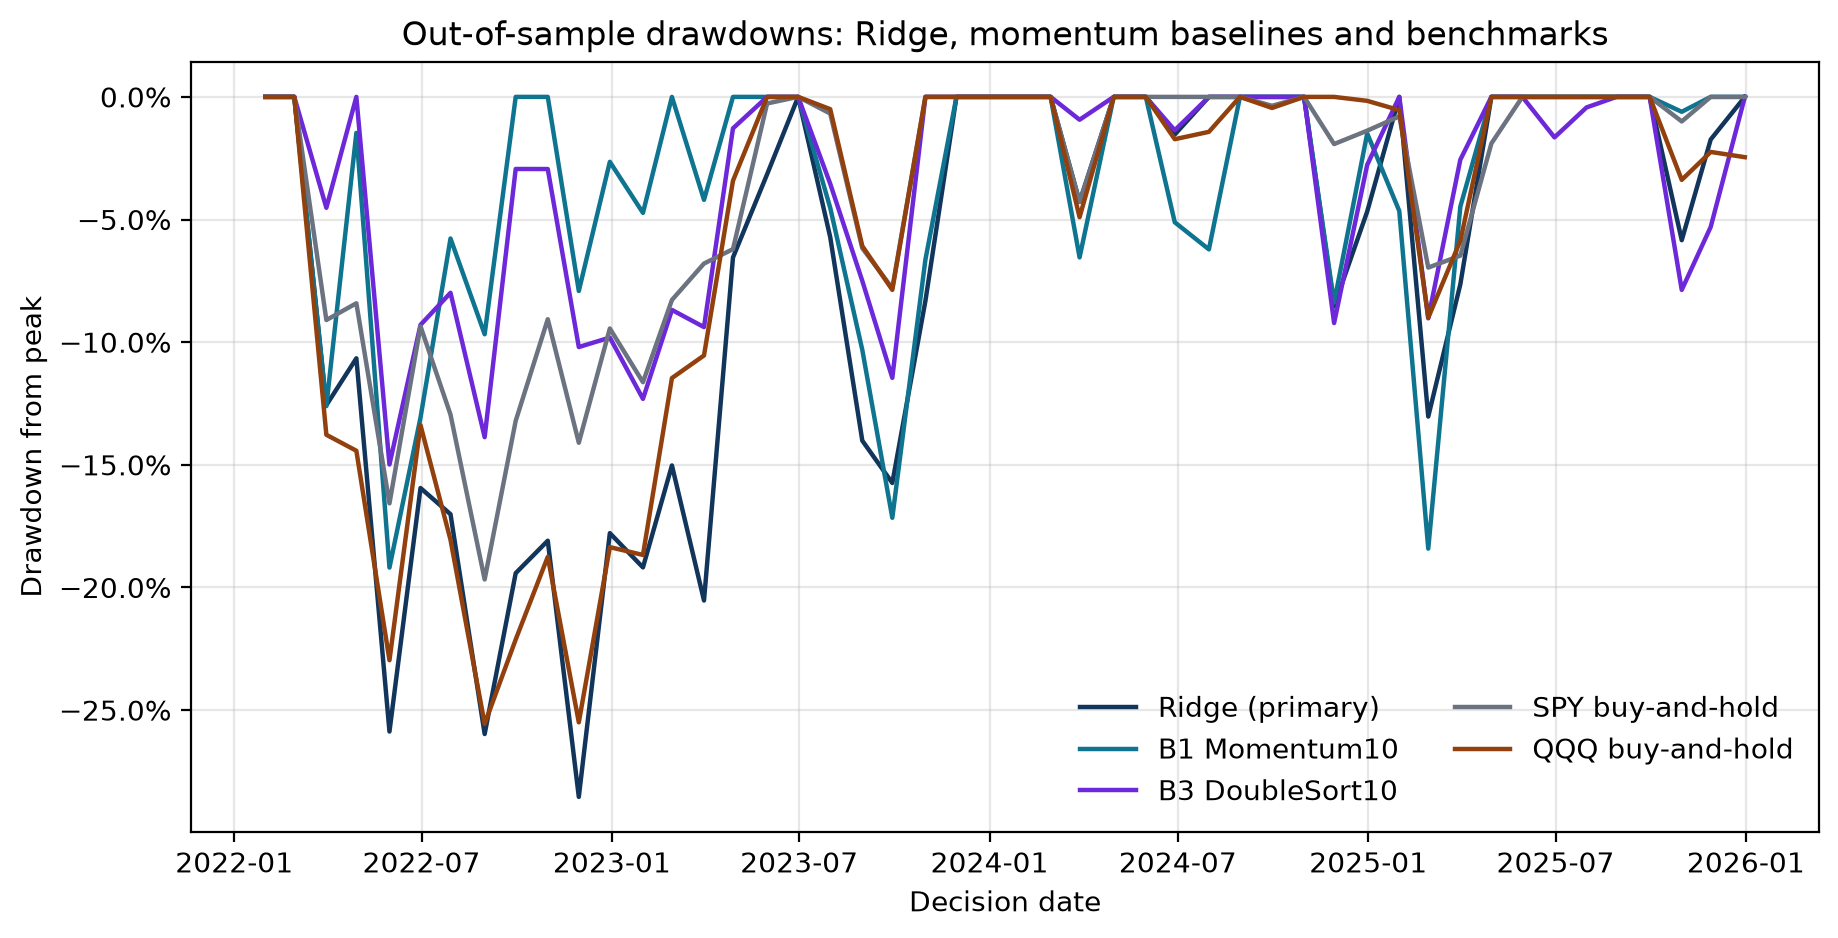

**Figure 5. Annual net returns.**

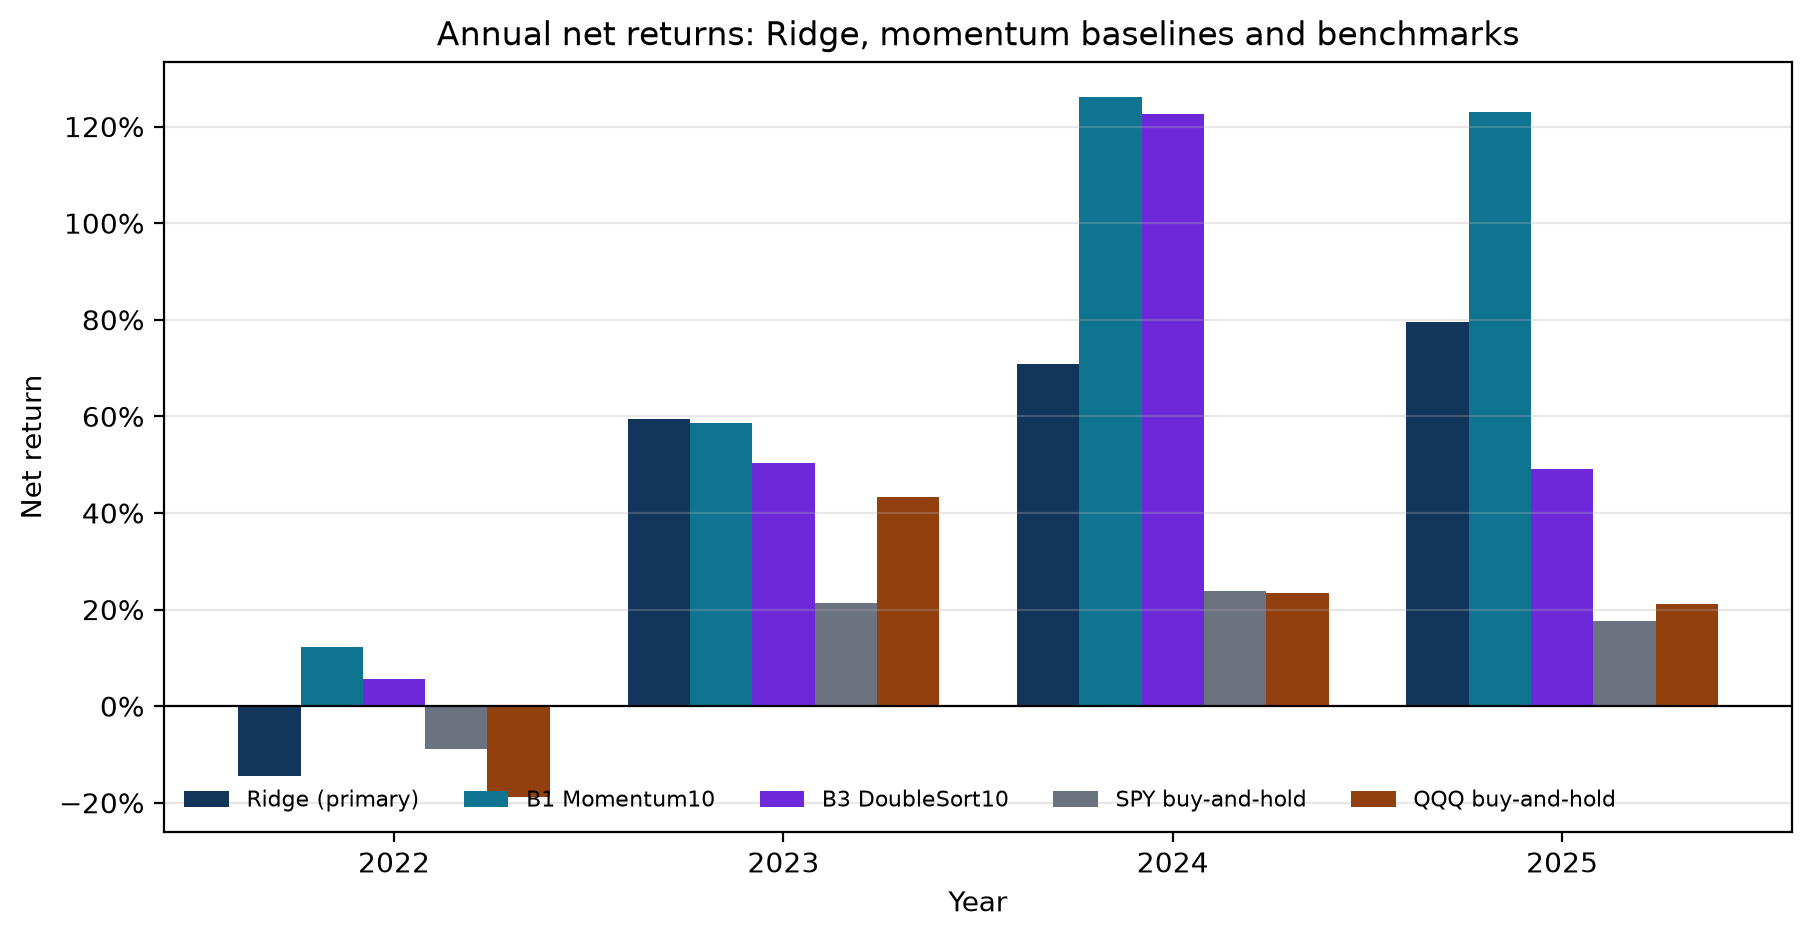

**Figure 6. Risk-adjusted performance: Sharpe and volatility.**

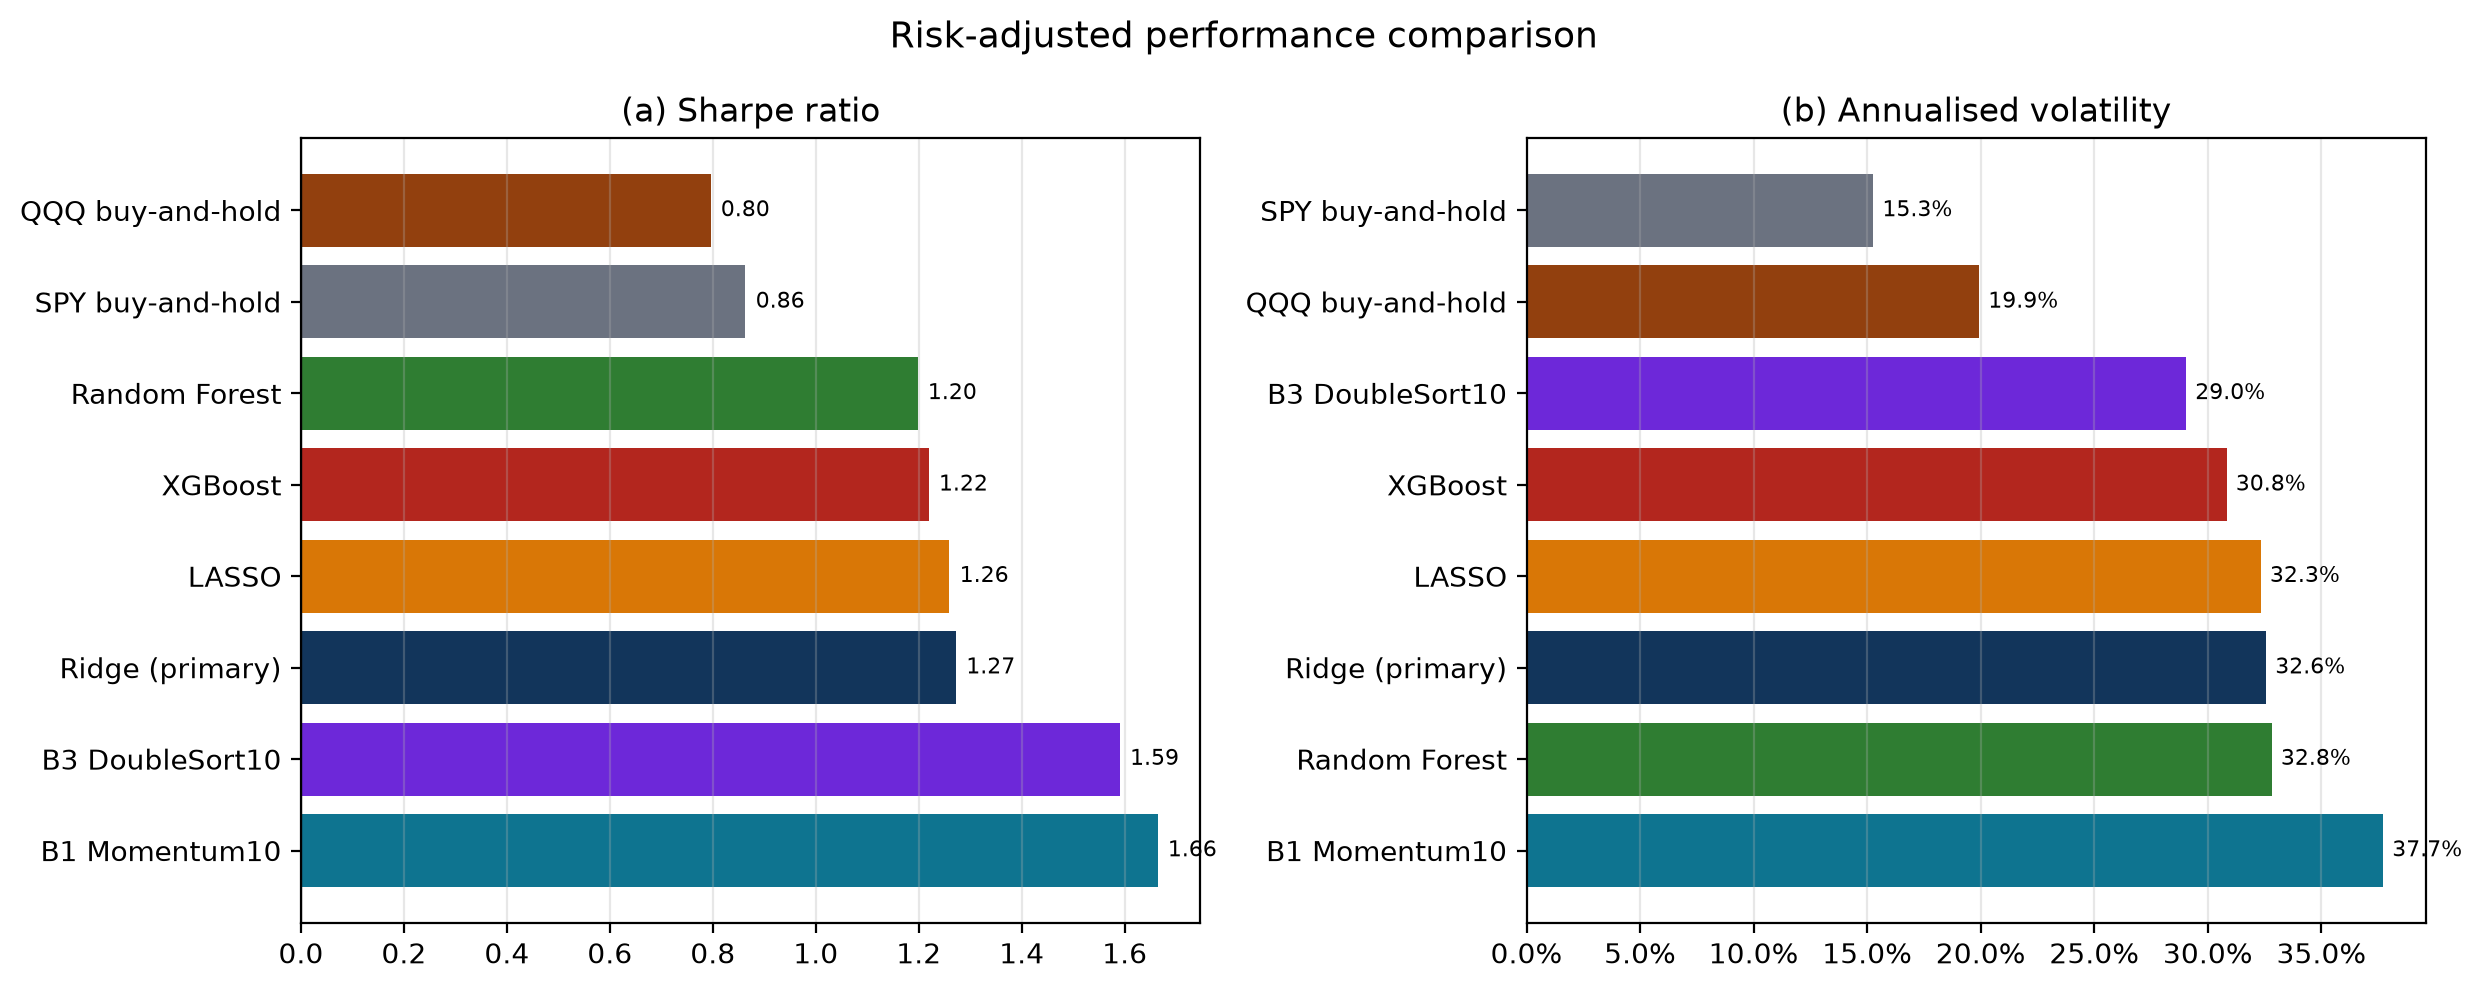

In [13]:
for name, caption in [
    ('fig1_four_model_wealth.png', 'Figure 1. Four ML models under the common trading rule.'),
    ('fig2_ridge_vs_benchmarks_wealth.png', 'Figure 2. Primary Ridge vs B1, B3, SPY and QQQ.'),
    ('fig3_eight_strategy_summary.png', 'Figure 3. Eight-strategy summary: CAGR and Sharpe.'),
    ('fig4_oos_drawdowns.png', 'Figure 4. Drawdowns: Ridge, B1, B3, SPY and QQQ.'),
    ('fig5_annual_returns.png', 'Figure 5. Annual net returns.'),
    ('fig6_risk_adjusted.png', 'Figure 6. Risk-adjusted performance: Sharpe and volatility.'),
]:
    display(Markdown(f'**{caption}**'))
    display(Image(filename=str(resolve(cfg['paths']['oos_figures']) / name), width=900))

**Figure 2** is the central result. Ridge compounds to roughly four times invested capital, while SPY and QQQ compound to roughly 1.6 and 1.75 times, so the active strategy comfortably beats both investable benchmarks. It does **not** beat the momentum baselines. B1 compounds to roughly nine times and B3 to roughly five times over the same window, with lower drawdowns.

**Figure 3** makes the same point on annualised and risk-adjusted scales. B1 has the highest CAGR and Sharpe; B3 is second on both; Ridge is the best of the four ML models but fourth overall. **Figure 4** shows why the ranking is not an artefact of terminal wealth: B1 and B3 also have shallower drawdowns than Ridge, so their advantage is not purchased with more risk. **Figure 5** shows that the baseline advantage is not uniform. Ridge led in 2023 (59.5% versus 58.6% for B1 and 50.3% for B3), but B1 and B3 captured much larger returns in 2024, and B1 also led in 2025. In 2022, a down year, both momentum baselines were positive while Ridge fell 14.4%. **Figure 6** shows that Ridge's volatility (32.6%) is lower than B1's (37.7%) and higher than B3's (29.0%), so the Sharpe gap is not a simple volatility story: B3 earned more per unit of risk with lower volatility and a much shallower drawdown.

The comparison of Ridge and B3 is the cleanest evidence on the forecasting question. Within the same candidate pool and execution convention, the Ridge ranking underperforms a simple momentum ranking by about 8.5 percentage points of CAGR and 0.32 of Sharpe, while turning over more (1.26 versus 0.94 per month). In this sample, the machine-learning ranking did not add value over momentum inside the screened pool. B1's larger advantage comes from a different candidate universe as well as a different ranking, so it cannot be attributed to ranking alone.

In [14]:
annual = eight_result['annual']
display((annual * 100).round(2))

ridge_row = metrics8.set_index('strategy').loc['ridge']
for strategy in ['B1_Momentum10', 'B3_MomentumDoubleSort10', 'SPY', 'QQQ']:
    row = metrics8.set_index('strategy').loc[strategy]
    print(f"Ridge vs {STRATEGY_DISPLAY[strategy]}: "
          f"CAGR {ridge_row.annualized_return:.2%} vs {row.annualized_return:.2%} "
          f"(difference {ridge_row.annualized_return - row.annualized_return:+.2%}); "
          f"Sharpe {ridge_row.sharpe_ratio:.2f} vs {row.sharpe_ratio:.2f}; "
          f"MaxDD {ridge_row.max_drawdown:.2%} vs {row.max_drawdown:.2%}")

strategy,B1_Momentum10,B3_MomentumDoubleSort10,QQQ,SPY,lasso,rf,ridge,xgb
decision_date,,,,,,,,
2022,12.33,5.63,-18.79,-8.82,-13.62,-10.32,-14.36,-6.20
2023,58.61,50.35,43.23,21.42,51.08,53.79,59.52,45.41
2024,126.14,122.68,23.34,23.86,74.27,58.26,70.77,53.13
2025,122.99,49.00,21.10,17.72,79.51,75.88,79.47,75.96


Ridge vs B1 Momentum10: CAGR 43.04% vs 73.13% (difference -30.09%); Sharpe 1.27 vs 1.66; MaxDD -28.54% vs -19.19%
Ridge vs B3 DoubleSort10: CAGR 43.04% vs 51.51% (difference -8.47%); Sharpe 1.27 vs 1.59; MaxDD -28.54% vs -14.99%
Ridge vs SPY buy-and-hold: CAGR 43.04% vs 12.72% (difference +30.33%); Sharpe 1.27 vs 0.86; MaxDD -28.54% vs -19.67%
Ridge vs QQQ buy-and-hold: CAGR 43.04% vs 14.81% (difference +28.23%); Sharpe 1.27 vs 0.80; MaxDD -28.54% vs -25.56%


## 11. Interpretation and Limitations

**Does Ridge improve prediction relative to the other ML models?** It has the highest OOS Sharpe and CAGR among the four, and it has the highest validation Rank IC. Its OOS rank IC (0.062) is second to Random Forest (0.088), and its MSE advantage over LASSO is small. It is not a decisive winner. The four models produce highly correlated portfolios because they share the candidate pool and features, and the test window is only 48 monthly observations.

**Does Ridge outperform SPY and QQQ?** Yes, by a large margin on CAGR and Sharpe, and after costs. But the strategy carries roughly twice the market's volatility and deeper drawdowns. Part of the excess return is compensation for that risk, and part may reflect the survivorship-biased universe.

**Does Ridge outperform B1 and B3?** No. Both momentum baselines have higher CAGR, higher Sharpe and lower maximum drawdown. The result is consistent across terminal wealth, annual returns, drawdown and risk-adjusted metrics. It is not a marginal difference that could be attributed to a single month.

**Is the evidence consistent across metrics?** Yes for the baseline comparison: B1 and B3 dominate Ridge on CAGR, Sharpe, drawdown and turnover. The four-model comparison is much closer and should be described as inconclusive rather than as a Ridge victory.

**Does Ridge add value beyond momentum stock selection?** Within the same thirty-candidate pool, no. Ridge's ranking is worse than momentum's in this sample. The machine-learning model does add value relative to holding the market, but that value is also available from a simple momentum rule with lower turnover.

**What could explain the differences?** Candidate-universe design matters: B1 selects from the full liquid universe, while Ridge and B3 are restricted to the double-sorted pool. Ranking method matters: B3's momentum ranking beat Ridge's predicted ranking within the same pool. Transaction costs matter: Ridge turns over more than both baselines, and the reported returns are already net of those costs. Market conditions matter: 2024–2025 contained strong persistent trends that favoured momentum. None of these explanations can be separated cleanly with one four-year test window.

**What are the limitations of the primary strategy?** Weak return predictability, a small evaluation sample, correlated monthly observations, model uncertainty, constant cost assumptions, survivorship bias, full equity beta without a risk overlay, and a static model that is never retrained during the test period. The validation evidence is also mildly optimistic because the same window is used to compare models.

The honest conclusion is that Ridge is a reasonable economic model and a defensible primary research choice, but this sample does not show that it improves on simpler momentum rules. Reporting that result is more useful than selecting a different strategy after seeing the test period.

## 12. Exploratory Ridge Strategy Extensions

The main OOS results motivate a separate exploratory question: can Ridge-based portfolio construction be improved by changing the candidate universe, the screening rule, the ranking, the weighting, or the diversification constraints? The original exploratory extension answers this with six investable sleeves plus SPY and QQQ.

| Code | Selection | Weighting |
|---|---|---|
| B1_Momentum10 | Momentum Top 10 from the liquid universe | Equal 10% |
| B2_Momentum30 | Momentum Top 30 from the liquid universe | Equal 1/30 |
| B3_MomentumDoubleSort10 | Momentum Top 10 within the 3×3 pool | Equal 10% |
| R1_RidgeWeighted10 | Same stocks as B1 | Ridge-prediction-proportional, 20% cap |
| R2_RidgeFree60 | Ridge Top 10 from 60 momentum candidates | Equal 10% |
| R3_RidgeQuota343 | Ridge 3/4/3 within High/Medium/Low momentum | Equal 10% |
| SPY, QQQ | Buy-and-hold | Fully invested |

R1 is *not* the primary strategy: it uses momentum selection and prediction-based weights. The primary strategy remains the 3×3 screen → Ridge Top-10 → equal-weight rule, and its authoritative OOS result is the one reported in Section 10.

These analyses are exploratory. Their design was informed by previously viewed out-of-sample results, so they do not provide fresh independent confirmation. They are reported for economic insight, not as replacements for the primary strategy.

,strategy,annualized_return,annualized_volatility,sharpe_rf0,max_drawdown,avg_two_way_turnover,total_cost
4,R1_RidgeWeighted10,0.8789,0.4493,1.6424,-0.2147,0.8032,0.0771
0,B1_Momentum10,0.7313,0.3772,1.6638,-0.1919,0.6504,0.0624
2,B3_MomentumDoubleSort10,0.5151,0.2904,1.5904,-0.1499,0.9382,0.0901
5,R2_RidgeFree60,0.3767,0.3986,1.0052,-0.4663,1.0760,0.1033
1,B2_Momentum30,0.3140,0.2585,1.1928,-0.1733,0.6196,0.0595
6,R3_RidgeQuota343,0.2253,0.3326,0.7780,-0.3899,1.4666,0.1408
3,QQQ,0.1481,0.1993,0.7955,-0.2556,0.0208,0.0020
8,SPY,0.1272,0.1527,0.8632,-0.1967,0.0208,0.0020


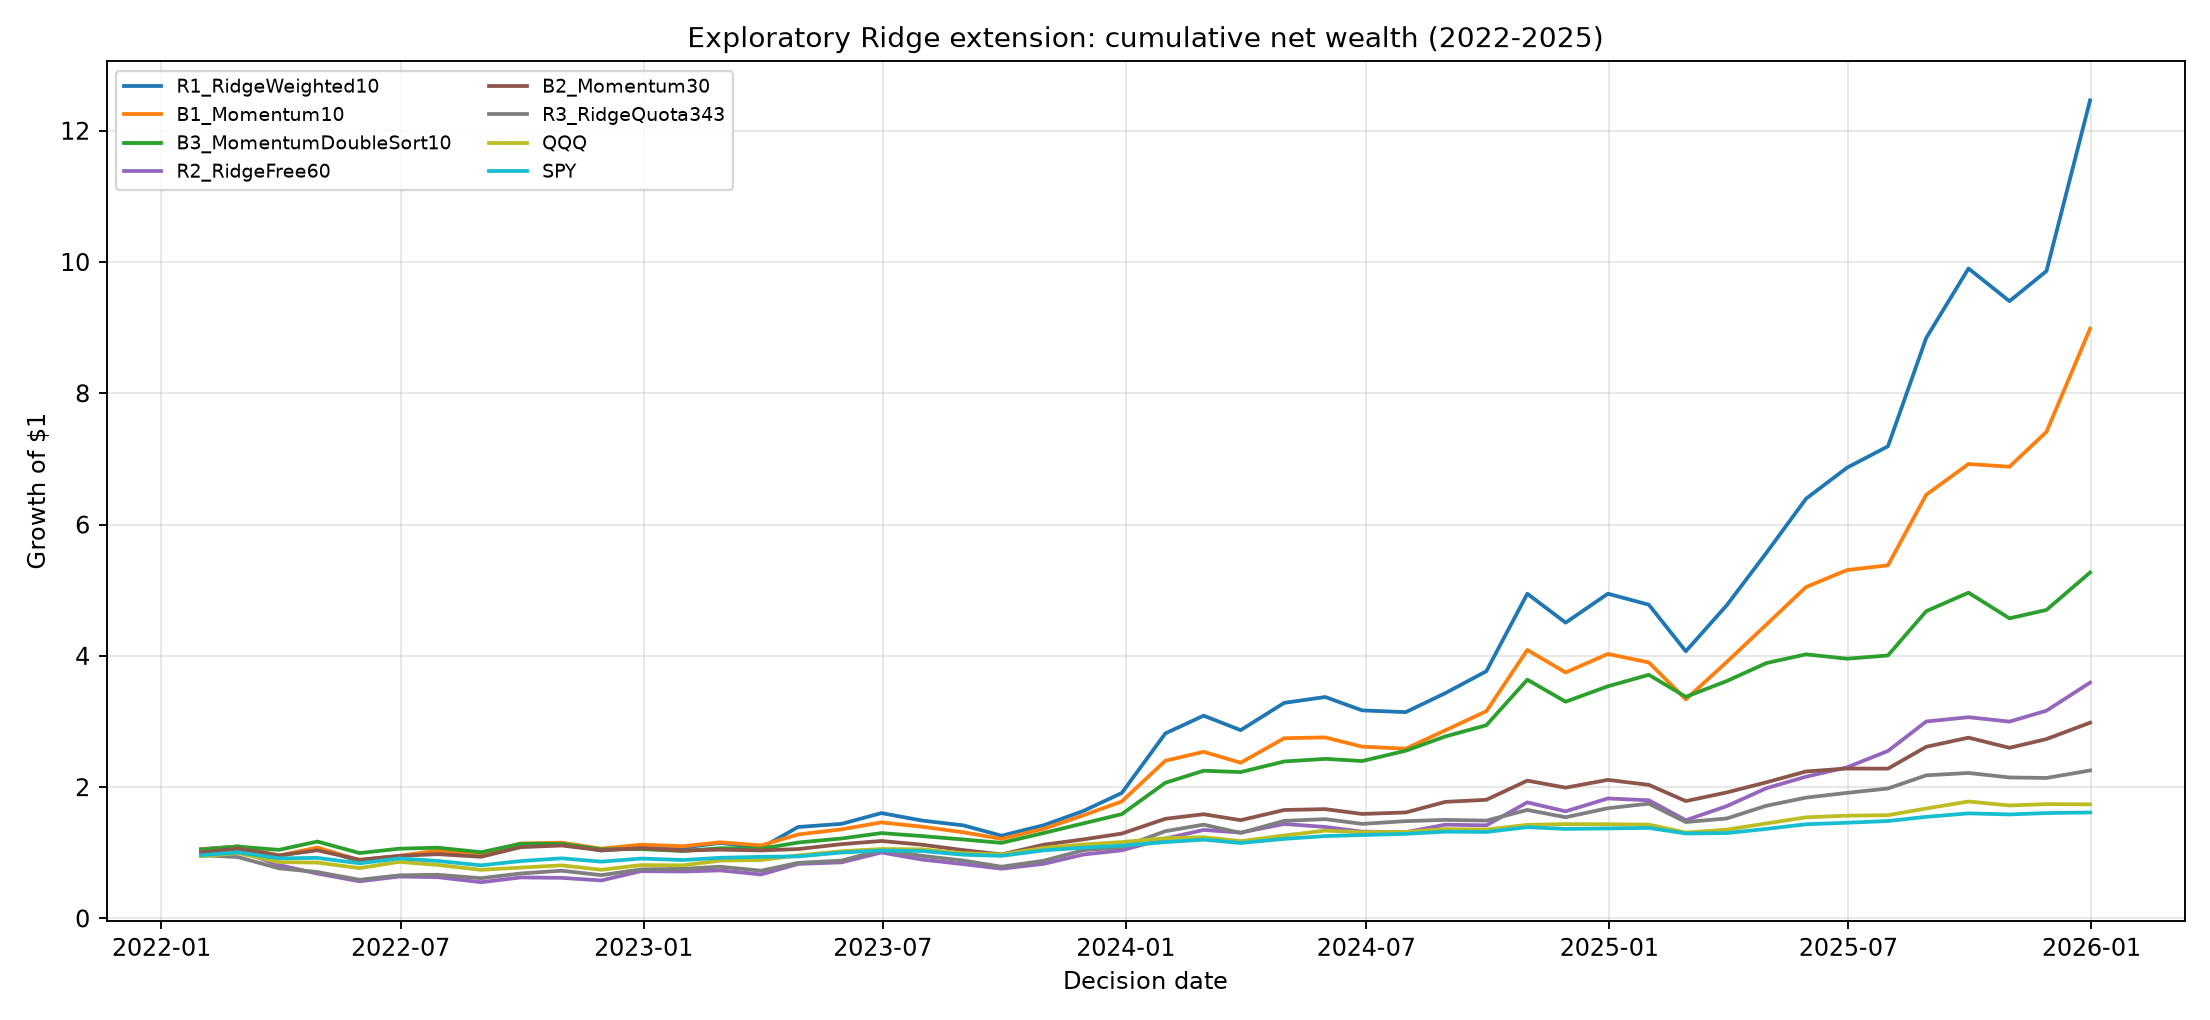

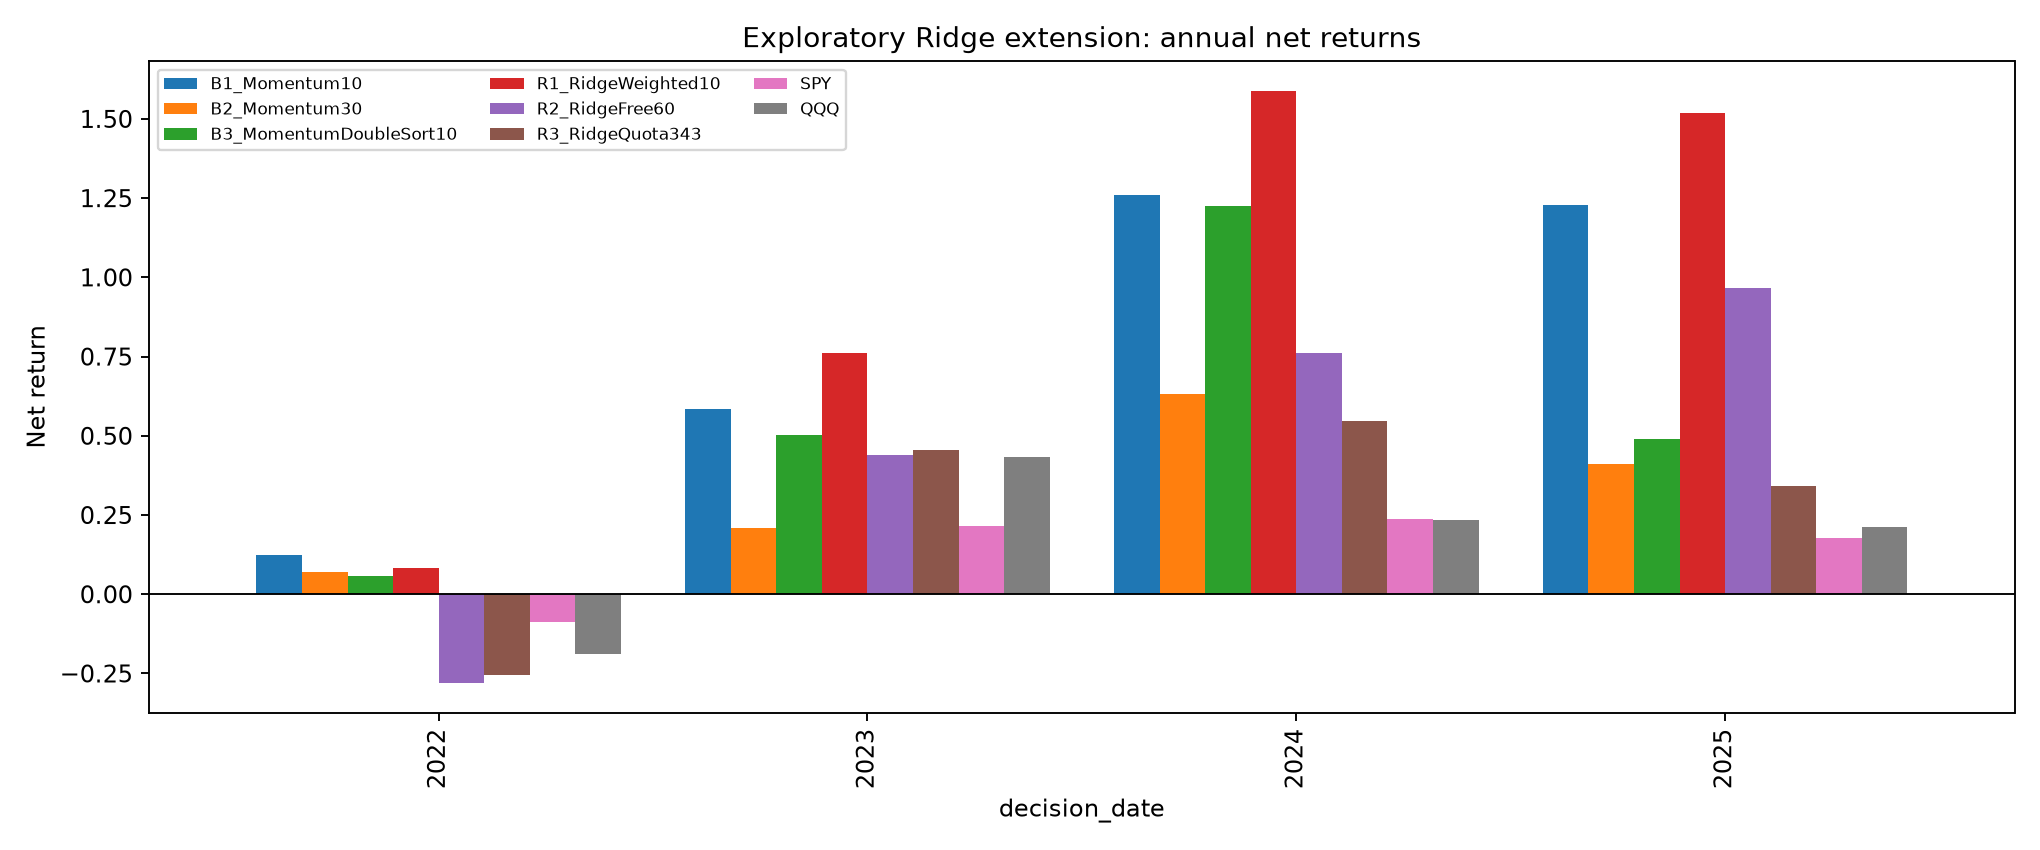

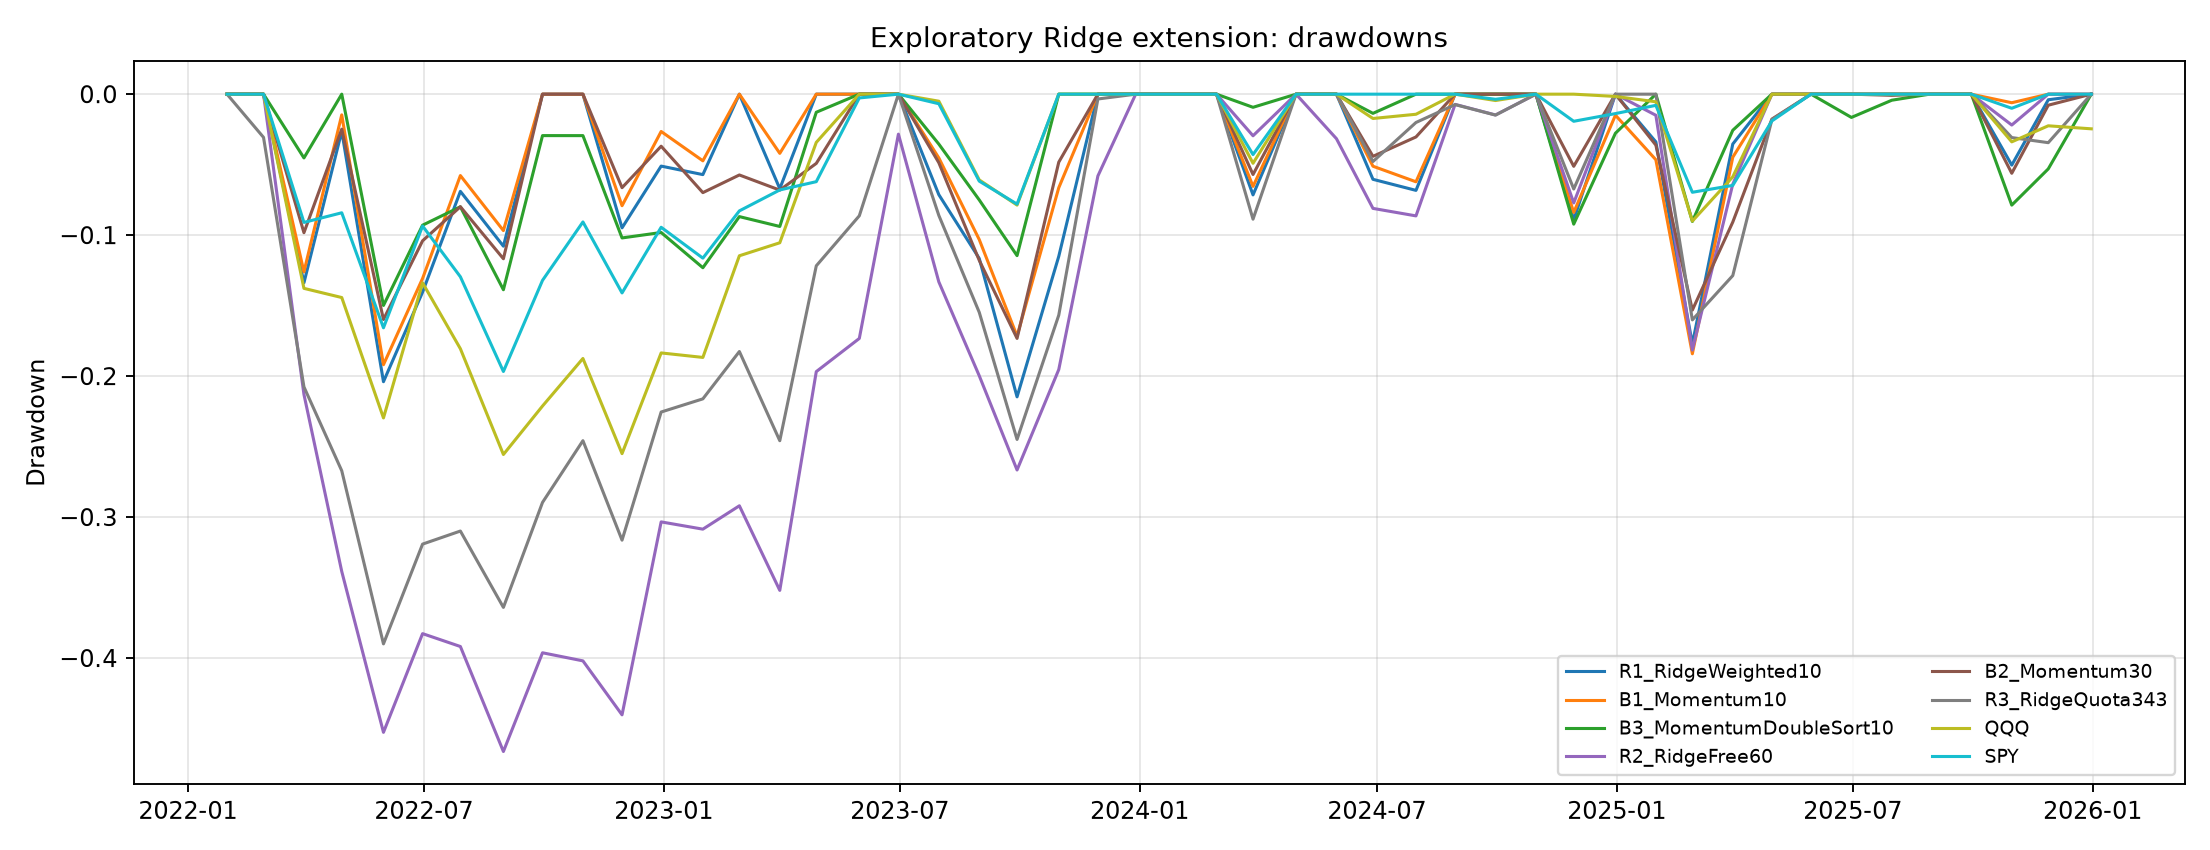

In [15]:
extension_summary = extension_result['public_summary']
display(extension_summary[[
    'strategy', 'annualized_return', 'annualized_volatility', 'sharpe_rf0',
    'max_drawdown', 'avg_two_way_turnover', 'total_cost',
]].round(4))
for name in ['extension_cumulative_wealth.png', 'extension_annual_returns.png', 'extension_drawdowns.png']:
    display(Image(filename=str(resolve(cfg['paths']['ridge_extension_figures']) / name), width=900))

The extension illustrates a distinction that is easy to miss. R1 and B1 hold the same stocks; their difference is weighting. R1's prediction-proportional weights raise absolute return but also raise volatility and turnover, and its Sharpe is slightly below B1's. The primary Ridge strategy and B3 share the candidate pool; their difference is the ranking method, and B3's momentum ranking wins on Sharpe and drawdown in this sample. Neither result overturns the primary finding: weighting and ranking adjustments can change absolute performance, but they do not consistently improve risk-adjusted performance, and they were designed with knowledge of earlier results.

The extension also shows why coefficient shrinkage is not portfolio allocation. Ridge's L2 penalty stabilises the forecast; it says nothing about position sizing. R1's 20% cap is a separate portfolio constraint applied after the forecast, and its effect on turnover and concentration is an allocation question, not a regularisation question.

## 13. Conclusion

The project set out to test whether Ridge regression on economically motivated predictors can produce useful cross-sectional rankings for a systematic equity portfolio. The evidence is mixed and informative.

Ridge produces a usable ranking. Under the unchanged Top-10 equal-weight rule it earns a 43.0% net CAGR and a 1.27 Sharpe over 2022–2025, versus 12.7% and 0.86 for SPY and 14.8% and 0.80 for QQQ. It also has the highest OOS Sharpe and CAGR among the four ML models, although Random Forest has the higher OOS rank IC.

The ranking does not beat simple momentum. B1 earns 73.1% CAGR with a 1.66 Sharpe and a 19.2% maximum drawdown; B3 earns 51.5% with a 1.59 Sharpe and a 15.0% drawdown. Within the same candidate pool, the Ridge ranking underperforms the momentum ranking by about 8.5 percentage points of CAGR and 0.32 of Sharpe, with higher turnover.

The defensible conclusion is therefore not that Ridge is the best strategy in the sample. It is that Ridge is an economically motivated model with diagnostic support, that it adds value relative to passive benchmarks, and that the evidence does not establish incremental value over momentum-based selection. That is a substantive research finding, and it is reported without selecting an alternative strategy after seeing the test period.

Future work should extend the sample, test rolling retraining, add point-in-time constituent data, model costs and capacity more carefully, and evaluate whether the Ridge ranking adds value conditionally on market regime or on the dispersion of momentum signals. None of those extensions is claimed here.

In [16]:
summary_table = pd.DataFrame([
    ('Primary model', primary_contract['primary_model']),
    ('Primary hyperparameters', json.dumps(primary_contract['selected_hyperparameters'], sort_keys=True)),
    ('Validation MSE winner (historical)', primary_contract['historical_automatic_selection']['selected_model']),
    ('Primary designation policy', primary_contract['policy']),
    ('Clean pre-registration', primary_contract['clean_preregistration']),
    ('Ridge OOS CAGR / Sharpe', f"{ridge_row.annualized_return:.2%} / {ridge_row.sharpe_ratio:.2f}"),
    ('B1 OOS CAGR / Sharpe', f"{metrics8.set_index('strategy').loc['B1_Momentum10','annualized_return']:.2%} / {metrics8.set_index('strategy').loc['B1_Momentum10','sharpe_ratio']:.2f}"),
    ('B3 OOS CAGR / Sharpe', f"{metrics8.set_index('strategy').loc['B3_MomentumDoubleSort10','annualized_return']:.2%} / {metrics8.set_index('strategy').loc['B3_MomentumDoubleSort10','sharpe_ratio']:.2f}"),
    ('SPY OOS CAGR / Sharpe', f"{metrics8.set_index('strategy').loc['SPY','annualized_return']:.2%} / {metrics8.set_index('strategy').loc['SPY','sharpe_ratio']:.2f}"),
], columns=['Item', 'Value'])
display(summary_table)

,Item,Value
0,Primary model,ridge
1,Primary hyperparameters,"{""alpha"": 1000.0}"
2,Validation MSE winner (historical),lasso
3,Primary designation policy,ridge_primary_economic_designation
4,Clean pre-registration,False
5,Ridge OOS CAGR / Sharpe,43.04% / 1.27
6,B1 OOS CAGR / Sharpe,73.13% / 1.66
7,B3 OOS CAGR / Sharpe,51.51% / 1.59
8,SPY OOS CAGR / Sharpe,12.72% / 0.86


## 14. Reproducibility and AI-Use Declaration

**Project structure.** Source code is under `src/`, configuration under `config/`, tests under `tests/`, results under `results/`, the academic report under `report/`, and the executed notebook under `notebooks/`.

**Environment.** The project runs on Python 3.11 with numpy, pandas, scikit-learn, xgboost, matplotlib, PyYAML and joblib. Exact versions are printed below. The random seed is 42.

**Commands.**

```bash
python run_pipeline.py --stage data
python run_pipeline.py --stage validation
python run_pipeline.py --stage designate --approve
python run_pipeline.py --stage refit
python run_pipeline.py --stage oos
python run_pipeline.py --stage score
python run_pipeline.py --stage extension
python run_pipeline.py --stage eight
python run_tests.py --notebook
```

**Output locations.** Validation tables and fifteen figures under `results/validation/`; OOS tables and figures under `results/oos/` and `results/oos/eight_strategy/`; extension tables and figures under `results/extensions/`; diagnostics under `results/diagnostics/`; serialized models under `results/models/refit/`; report source and PDF under `report/` (Project2_Report.tex/.pdf).

**AI-use declaration.** This revision was prepared with AI assistance (DeepSeek Harness) for code restructuring, test generation, diagnostic integration, figure production and LaTeX drafting. All numerical results were produced by executing the repository code on the historical data snapshot. The original strategy, data pipeline and exploratory extension were authored by the project team. The AI assistant did not have access to any data beyond the supplied project files, and no result was fabricated or manually inserted.

**Disclosure of research chronology.** The original project pre-specified Ridge. A later engineering revision introduced an automatic minimum-MSE rule that selected LASSO, and out-of-sample results were reviewed during that revision. The Ridge designation was restored afterwards on economic and diagnostic grounds. The primary-model contract records `clean_preregistration: false` and `designation_informed_by_prior_oos_review: true`. No test-period metric was used to choose Ridge or its `alpha`, but the designation is not a clean pre-registration and should not be presented as one.

In [17]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

env = environment_info()
display(pd.DataFrame([
    ('python', env['packages']['python']),
    ('numpy', env['packages']['numpy']),
    ('pandas', env['packages']['pandas']),
    ('scikit-learn', env['packages']['sklearn']),
    ('xgboost', env['packages']['xgboost']),
    ('matplotlib', env['packages']['matplotlib']),
    ('random seed', cfg['project']['random_seed']),
    ('config hash', primary_contract['config_hash']),
    ('primary contract run id', primary_contract['run_id']),
    ('designation timestamp (UTC)', primary_contract['designation_timestamp_utc']),
    ('historical LASSO archive', str((resolve(cfg['paths']['validation']) / 'archive' / 'selection_contract_lasso_min_mse.json').relative_to(PROJECT_ROOT))),
], columns=['Item', 'Value']))

artefacts = sorted([
    *resolve(cfg['paths']['validation']).glob('*.csv'),
    *resolve(cfg['paths']['validation']).glob('*.json'),
    *resolve(cfg['paths']['validation_figures']).glob('*.png'),
    *resolve(cfg['paths']['oos']).glob('*.csv'),
    *resolve(cfg['paths']['oos']).glob('*.json'),
    *resolve(cfg['paths']['oos_figures']).glob('*.png'),
    *resolve(cfg['paths']['eight_strategy']).glob('*.csv'),
    *resolve(cfg['paths']['eight_strategy']).glob('*.json'),
    *resolve(cfg['paths']['ridge_extension']).glob('*.csv'),
    *resolve(cfg['paths']['research_diagnostics']).glob('*.png'),
])
display(pd.DataFrame({
    'artefact': [str(p.relative_to(PROJECT_ROOT)) for p in artefacts],
    'bytes': [p.stat().st_size for p in artefacts],
}))
print('Primary contract sha256:', sha256(resolve(cfg['paths']['validation']) / 'primary_model_contract.json'))
print('Notebook executed successfully; all results are regenerated from the packaged data snapshot.')

,Item,Value
0,python,3.11.4
1,numpy,1.26.4
2,pandas,2.2.3
3,scikit-learn,1.9.1
4,xgboost,3.2.0
5,matplotlib,3.11.2
6,random seed,42
7,config hash,57d05bade96129690d8d5b114866e867a5ec6db9af670e...
8,primary contract run id,ridge-8e366135479d9a39
9,designation timestamp (UTC),2026-11-11T12:30:02Z


,artefact,bytes
0,results/diagnostics/coefficient_trajectories.png,1705860
1,results/diagnostics/feature_correlation_heatma...,287685
2,results/diagnostics/report_correlation_heatmap...,125500
3,results/diagnostics/report_stability_compariso...,73557
4,results/diagnostics/stability_comparison.png,141641
...,...,...
72,results/validation/validation_monthly_returns.csv,11364
73,results/validation/validation_portfolio_metric...,4051
74,results/validation/validation_prediction_metri...,1934
75,results/validation/validation_predictions.csv,482223


Primary contract sha256: 18c1596432f4511374215391501fba4a3eba00ac06b9a3042fcc771c1e08c48d
Notebook executed successfully; all results are regenerated from the packaged data snapshot.


---

All results are for academic research and historical backtesting only. No live trading was conducted. The backtest is not a forecast of future returns, and the survivorship and cost limitations stated above apply to every reported performance figure.